# Previsão de acidentes graves em rodovias federais brasileiras com dados abertos da PRF

**Projeto Final — Inteligência Artificial (UFPI) — Prof. Dr. Pedro Almir Martins de Oliveira**

| | |
|---|---|
| **Autor** | João Pedro Pereira da Luz — matrícula 20239045988 |
| **Objetivo** | Avaliar se é possível prever, com as informações de local, horário e condições da via, se um acidente em rodovia federal terá vítima grave ou fatal. |
| **Pergunta de pesquisa** | Quanto da gravidade de um acidente é previsível apenas pelo contexto (onde, quando e em que condições ele ocorre), e quanto do desempenho relatado em trabalhos semelhantes depende de informações que só existem depois do acidente? |
| **Tipo de aprendizado** | Supervisionado — classificação binária (acidente *grave* × *não grave*). |
| **Dados** | Dados Abertos da Polícia Rodoviária Federal (PRF), acidentes agrupados por ocorrência, 2021–2025. |

Este notebook é ao mesmo tempo o código e o relatório técnico do projeto. Ele baixa os dados direto da fonte pública e executa do início ao fim sem arquivos locais.

## 1. Descrição do problema

**Contexto.** A PRF registra dezenas de milhares de acidentes por ano nas rodovias federais. Uma parte deles deixa mortos ou feridos graves, e é nesses casos que o tempo de resposta do socorro e a fiscalização preventiva mais importam.

**Decisão apoiada.** Um modelo que estime o risco de um acidente ser grave a partir do contexto (trecho, horário, clima, tipo de pista) pode apoiar duas decisões: onde e quando concentrar fiscalização e equipes de atendimento, e que prioridade dar a uma ocorrência recém-comunicada, antes de a equipe chegar ao local.

**Público beneficiado.** Planejamento operacional da PRF, serviços de atendimento de emergência (SAMU, bombeiros) e concessionárias de rodovias.

**Limites do escopo.**
- A base só contém acidentes que **aconteceram e foram registrados**. O modelo estima a gravidade *dado que houve acidente*; ele não estima a probabilidade de um acidente ocorrer.
- Só rodovias federais. Vias estaduais e urbanas ficam de fora.
- O modelo encontra associações, não causas. Nada aqui autoriza afirmar que um fator *causa* a gravidade.

**Definição do rótulo.** Um acidente é **grave** quando tem pelo menos um morto ou um ferido grave (`mortos > 0` ou `feridos_graves > 0`). Os demais são **não graves**. Juntar mortos e feridos graves dá uma classe positiva com volume suficiente para modelar e corresponde aos casos que exigem atendimento de maior complexidade.

## 2. Ambiente e reprodutibilidade

Todas as etapas aleatórias usam a mesma semente (`SEMENTE = 42`). A célula abaixo imprime as versões das bibliotecas usadas nesta execução. O notebook só depende de bibliotecas que já vêm instaladas no Google Colab e no Kaggle.

In [30]:
import io
import sys
import time
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, accuracy_score,
                             precision_recall_curve, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMENTE = 42
np.random.seed(SEMENTE)

print("Python      ", sys.version.split()[0])
for nome, modulo in [("pandas", pd), ("numpy", np), ("scikit-learn", sklearn), ("matplotlib", matplotlib)]:
    print(f"{nome:12s}", modulo.__version__)

# Estilo único para todos os gráficos
AZUL, LARANJA, VERDE, AMARELO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False,
})
# Os textos de interpretação deste notebook citam os números obtidos com as versões abaixo (as do Google Colab
# em novembro de 2026). Com outras versões, alguns valores podem mudar na segunda ou terceira casa decimal.
VERSOES_DE_REFERENCIA = {"pandas": "2.2.3", "scikit-learn": "1.6.1"}
if pd.__version__ != VERSOES_DE_REFERENCIA["pandas"] or sklearn.__version__ != VERSOES_DE_REFERENCIA["scikit-learn"]:
    print("\nAVISO: versões diferentes das de referência", VERSOES_DE_REFERENCIA,
          "— confira os números citados nos textos contra as saídas desta execução.")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

Python       3.13.18
pandas       2.2.3
numpy        2.4.6
scikit-learn 1.6.1
matplotlib   3.10.0


## 3. Dados

| Item | Descrição |
|---|---|
| **Fonte** | Polícia Rodoviária Federal — [Dados Abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf), seção "Acidentes", arquivos "Agrupados por ocorrência". |
| **Condição de uso** | A PRF publica o conjunto como dado aberto, definido na própria página como "sem restrição de licenças, patentes ou mecanismos de controle", que "qualquer pessoa pode livremente usar, reutilizar e redistribuir". Não exige cadastro nem login. |
| **Unidade de análise** | Cada linha é um acidente (uma ocorrência registrada em Boletim de Acidente de Trânsito). |
| **Período usado** | 2021 a 2025 (cinco anos completos). |
| **Formato** | Um arquivo ZIP por ano, hospedado pela PRF no Google Drive, contendo um CSV separado por `;` em codificação Latin-1. |

**Por que a partir de 2021.** Os trabalhos relacionados mais recentes usam o período 2020–2024, e o formulário de registro da PRF mudou ao longo dos anos. Cinco anos recentes dão volume suficiente e permitem separar treino, validação e teste por ano.

**Limitações conhecidas da fonte.**
- A PRF avisa que os números dos dados abertos podem divergir dos anuários estatísticos, porque os registros são revisados depois da publicação. Os arquivos podem mudar entre uma execução e outra deste notebook.
- Os campos são preenchidos pelo policial no local. Há categorias como "Ignorado" e "Não Informado", e a forma de preenchimento mudou com o tempo (mostrado na Seção 4).
- Acidentes sem acionamento da PRF não aparecem. Acidentes leves tendem a ser sub-registrados, o que infla a proporção de graves em relação à realidade.

A célula abaixo baixa os cinco arquivos direto dos links publicados na página da PRF e guarda uma cópia na pasta `dados/` para não baixar de novo.

In [31]:
# Identificadores dos arquivos no Google Drive, copiados da página de Dados Abertos da PRF
# (linhas "Documento CSV de Acidentes <ano> (Agrupados por ocorrência)"), consultada em 16/11/2026.
ARQUIVOS_PRF = {
    2021: "12xH8LX9aN2gObR766YN3cMcuycwyCJDz",
    2022: "1PRQjuV5gOn_nn6UNvaJyVURDIfbSAK4-",
    2023: "1-WO3SfNrwwZ5_l7fRTiwBKRw7mi1-HUq",
    2024: "14lB0vqMFkaZj8HZ44b0njYgxs9nAN8KO",
    2025: "1-G3MdmHBt6CprDwcW99xxC4BZ2DU5ryR",
}
PASTA_DADOS = Path("dados")
PASTA_DADOS.mkdir(exist_ok=True)


def baixar_ano(ano):
    """Baixa o ZIP de um ano (se ainda não estiver na pasta) e devolve o DataFrame."""
    destino = PASTA_DADOS / f"datatran{ano}.zip"
    if not destino.exists():
        url = f"https://drive.google.com/uc?export=download&id={ARQUIVOS_PRF[ano]}"
        requisicao = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        conteudo = urllib.request.urlopen(requisicao, timeout=120).read()
        if not conteudo.startswith(b"PK"):
            raise RuntimeError(
                f"O download de {ano} não devolveu um arquivo ZIP. Baixe manualmente em "
                "https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf "
                f"e salve como {destino}.")
        destino.write_bytes(conteudo)
    with zipfile.ZipFile(destino) as z:
        with z.open(z.namelist()[0]) as f:
            df = pd.read_csv(f, sep=";", encoding="latin-1", low_memory=False)
    df["ano"] = ano
    return df


bruto = pd.concat([baixar_ano(ano) for ano in ARQUIVOS_PRF], ignore_index=True)
print(f"{len(bruto):,} acidentes, {bruto.shape[1] - 1} colunas originais mais a coluna 'ano' criada aqui".replace(",", "."))
bruto.groupby("ano").size().rename("acidentes").to_frame().T

342.670 acidentes. 30 colunas originais mais a coluna 'ano' criada aqui


ano,2021,2022,2023,2024,2025
acidentes,64567,64606,67766,73202,72529


### 3.1 Atributos

A tabela resume cada coluna: tipo, valores ausentes, número de valores distintos e um exemplo.

In [32]:
resumo = pd.DataFrame({
    "tipo": bruto.dtypes.astype(str),
    "ausentes": bruto.isna().sum(),
    "distintos": bruto.nunique(),
    "exemplo": bruto.iloc[0].astype(str),
})
resumo

,tipo,ausentes,distintos,exemplo
id,float64,0,342670,331730.0
data_inversa,object,0,1826,2021-01-01
dia_semana,object,0,7,sexta-feira
horario,object,0,1440,05:30:00
uf,object,0,27,SP
br,int64,0,126,116
km,object,0,9498,453
municipio,object,0,2051,REGISTRO
causa_acidente,object,0,76,Reação tardia ou ineficiente do condutor
tipo_acidente,object,0,18,Tombamento


As colunas se dividem em três grupos, e essa divisão orienta todo o restante do trabalho:

1. **Contexto** — onde, quando e em que condições: `data_inversa`, `dia_semana`, `horario`, `uf`, `br`, `km`, `latitude`, `longitude`, `fase_dia`, `sentido_via`, `condicao_metereologica`, `tipo_pista`, `tracado_via`, `uso_solo`.
2. **Dinâmica da ocorrência** — só se conhece depois que o acidente aconteceu e foi descrito: `tipo_acidente`, `causa_acidente`, `veiculos`, `pessoas`.
3. **Desfecho** — contagem de vítimas, de onde sai o rótulo: `mortos`, `feridos_graves`, `feridos_leves`, `feridos`, `ilesos`, `ignorados`, `classificacao_acidente`.

As colunas `municipio`, `regional`, `delegacia` e `uop` são identificadores administrativos com muitas categorias e redundantes com `uf`, `br`, `km` e as coordenadas; não são usadas.

### 3.2 Rótulo e verificações de qualidade

In [33]:
bruto["grave"] = ((bruto["mortos"] > 0) | (bruto["feridos_graves"] > 0)).astype(int)

print("Distribuição do rótulo (todos os anos):")
print(bruto["grave"].map({0: "não grave", 1: "grave"}).value_counts(normalize=True).round(3).to_string())

print("\nVerificações de qualidade:")
print("  linhas totalmente duplicadas ......", bruto.drop(columns=["ano", "grave"]).duplicated().sum())
print("  identificadores (id) repetidos ....", bruto["id"].duplicated().sum())
print("  feridos != leves + graves .........", (bruto["feridos"] != bruto["feridos_leves"] + bruto["feridos_graves"]).sum())
print("  classificacao_acidente ausente ....", bruto["classificacao_acidente"].isna().sum())
incoerente = ((bruto["classificacao_acidente"] == "Sem Vítimas") & (bruto["mortos"] + bruto["feridos"] > 0)).sum()
print("  'Sem Vítimas' com vítimas .........", incoerente)
soma_pessoas = bruto["mortos"] + bruto["feridos"] + bruto["ilesos"] + bruto["ignorados"]
divergente = (bruto["pessoas"] != soma_pessoas)
print(f"  pessoas != mortos+feridos+ilesos+ignorados .. {divergente.sum()} ({divergente.mean()*100:.1f}%)")
repetido = bruto.duplicated(["data_inversa", "horario", "uf", "br", "km", "tipo_acidente"]).sum()
print("  mesma data, hora, local e tipo ....", repetido)
hora_cheia = (bruto["horario"].str[3:5] == "00").mean() * 100
print(f"  horário registrado em hora cheia .. {hora_cheia:.1f}% (esperado sem arredondamento: 1,7%)")
cobertura = bruto.groupby("ano")["data_inversa"].agg(["min", "max"])
print("  todos os anos cobrem de 01/01 a 31/12:", bool((cobertura["min"].str[5:] == "01-01").all() and (cobertura["max"].str[5:] == "12-31").all()))

pd.crosstab(bruto["classificacao_acidente"].fillna("(ausente)"), bruto["grave"].map({0: "não grave", 1: "grave"}))

Distribuição do rótulo (todos os anos):
grave
não grave   0.717
grave       0.283

Verificações de qualidade:
  linhas totalmente duplicadas ...... 0
  identificadores (id) repetidos .... 0
  feridos != leves + graves ......... 0
  classificacao_acidente ausente .... 5
  'Sem Vítimas' com vítimas ......... 0
  pessoas != mortos+feridos+ilesos+ignorados .. 18541 (5.4%)
  mesma data, hora, local e tipo .... 77
  horário registrado em hora cheia .. 19.9% (esperado sem arredondamento: 1,7%)
  todos os anos cobrem de 01/01 a 31/12: True


grave,grave,não grave
classificacao_acidente,,
(ausente),3,2
Com Vítimas Fatais,24621,0
Com Vítimas Feridas,72252,188712
Sem Vítimas,0,57080


**Leitura.**
- **O que está íntegro.** Não há linhas nem identificadores duplicados, os cinco anos estão completos (de 1º de janeiro a 31 de dezembro) e as colunas de vítimas que definem o rótulo são coerentes: `feridos` é sempre a soma de leves e graves, e nenhum acidente "Sem Vítimas" tem vítimas. Os poucos valores ausentes ficam em `classificacao_acidente` e nas colunas administrativas, que não entram no modelo principal. Por isso nenhuma linha é descartada.
- **Inconsistência encontrada.** Em 5,4% dos acidentes, `pessoas` não é igual à soma de mortos, feridos, ilesos e ignorados (a soma é sempre maior). O rótulo não é afetado, porque depende só de `mortos` e `feridos_graves`. As colunas `pessoas` e `ignorados` entram apenas nos cenários B e C da Seção 8.2, e essa limitação deve ser lembrada ao interpretá-los.
- **Possíveis registros repetidos.** Há 77 acidentes com a mesma data, hora, local e tipo de outro registro (0,02% da base). Podem ser acidentes distintos no mesmo ponto ou o mesmo acidente registrado duas vezes; como não é possível distinguir e o volume é desprezível, foram mantidos.
- **Horário aproximado.** Cerca de 20% dos registros têm horário em hora cheia, contra 1,7% esperado se o minuto fosse registrado com exatidão. A hora do acidente é, em boa parte, uma estimativa do policial. Isso limita o quanto se pode extrair do atributo de horário.

A tabela cruzada mostra por que as colunas de desfecho não podem ser atributos: todo acidente "Com Vítimas Fatais" é grave por definição e todo "Sem Vítimas" é não grave. Usar essa coluna seria entregar a resposta ao modelo. A Seção 8 mede o tamanho desse efeito.

## 4. Preparação dos dados

A função `preparar` aplica transformações que dependem **apenas da própria linha** (conversão de tipos e criação de atributos). Nada aqui usa estatísticas calculadas sobre o conjunto, então pode ser aplicada antes da divisão sem risco de vazamento. As transformações que aprendem algo dos dados (padronização e codificação de categorias) ficam dentro do *pipeline* e são ajustadas só no treino (Seção 6).

| Decisão | Justificativa |
|---|---|
| `km`, `latitude`, `longitude` de texto para número | Vêm com vírgula decimal. |
| `horario` → hora decimal, mais `hora_sen` e `hora_cos` | A hora é cíclica: 23h e 0h são vizinhas. Seno e cosseno preservam essa vizinhança para a regressão logística. |
| `data_inversa` → `mes` e `fim_de_semana` | Captura sazonalidade e o padrão de fim de semana. |
| `tracado_via` → 12 indicadores (0/1) | O campo aceita vários valores juntos ("Reta;Declive"), o que gera mais de mil combinações. Separar em indicadores mantém a informação com 12 colunas. |
| `uso_solo` → `area_urbana` (0/1) | Na base, "Sim" indica trecho urbano. |
| `br` como categoria | O número da rodovia é um nome, não uma grandeza. |
| Categorias "Ignorado" e "Não Informado" mantidas | A falta de informação pode estar associada ao desfecho; descartar as linhas introduziria viés de seleção. |
| Sem remoção de *outliers* | Valores extremos de `veiculos` e `pessoas` são acidentes reais (engavetamentos, ônibus). As coordenadas foram conferidas contra os limites do território brasileiro. |

In [34]:
ELEMENTOS_TRACADO = ["Reta", "Curva", "Aclive", "Declive", "Interseção de Vias", "Rotatória", "Ponte",
                     "Viaduto", "Túnel", "Retorno Regulamentado", "Desvio Temporário", "Em Obras"]
NOME_TRACADO = {e: "tracado_" + e.lower().replace(" de vias", "").replace(" regulamentado", "")
                .replace(" temporário", "").replace(" ", "_").replace("ç", "c").replace("ã", "a").replace("ú", "u").replace("ó", "o")
                for e in ELEMENTOS_TRACADO}
REGIAO = {**dict.fromkeys(["AC", "AM", "AP", "PA", "RO", "RR", "TO"], "Norte"),
          **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Nordeste"),
          **dict.fromkeys(["DF", "GO", "MS", "MT"], "Centro-Oeste"),
          **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Sudeste"),
          **dict.fromkeys(["PR", "RS", "SC"], "Sul")}


def para_numero(coluna):
    return pd.to_numeric(coluna.astype(str).str.replace(",", ".", regex=False), errors="coerce")


def preparar(df):
    d = pd.DataFrame(index=df.index)
    d["ano"] = df["ano"]
    d["grave"] = df["grave"]

    # --- contexto: quando
    data = pd.to_datetime(df["data_inversa"])
    hora = pd.to_datetime(df["horario"], format="%H:%M:%S")
    d["hora"] = hora.dt.hour + hora.dt.minute / 60
    d["hora_sen"] = np.sin(2 * np.pi * d["hora"] / 24)
    d["hora_cos"] = np.cos(2 * np.pi * d["hora"] / 24)
    d["mes"] = data.dt.month
    d["dia_semana"] = df["dia_semana"]
    d["fim_de_semana"] = df["dia_semana"].isin(["sábado", "domingo"]).astype(int)
    d["fase_dia"] = df["fase_dia"]

    # --- contexto: onde
    d["uf"] = df["uf"]
    d["regiao"] = df["uf"].map(REGIAO)          # usada só na análise, não como atributo
    d["br"] = "BR-" + df["br"].astype(str)
    d["km"] = para_numero(df["km"])
    d["latitude"] = para_numero(df["latitude"])
    d["longitude"] = para_numero(df["longitude"])
    d["sentido_via"] = df["sentido_via"]

    # --- contexto: condições da via
    d["condicao_metereologica"] = df["condicao_metereologica"]
    d["tipo_pista"] = df["tipo_pista"]
    d["area_urbana"] = (df["uso_solo"] == "Sim").astype(int)
    partes = df["tracado_via"].fillna("").str.split(";")
    for elemento, nome in NOME_TRACADO.items():
        d[nome] = partes.apply(lambda lista, e=elemento: int(e in lista))

    # --- dinâmica da ocorrência (conhecida só depois do acidente)
    d["tipo_acidente"] = df["tipo_acidente"]
    d["causa_acidente"] = df["causa_acidente"]
    d["veiculos"] = df["veiculos"]
    d["pessoas"] = df["pessoas"]

    # --- desfecho (usado apenas na demonstração de vazamento da Seção 8)
    d["classificacao_acidente"] = df["classificacao_acidente"].fillna("(ausente)")
    d["feridos_leves"] = df["feridos_leves"]
    d["ilesos"] = df["ilesos"]
    d["ignorados"] = df["ignorados"]
    return d


dados = preparar(bruto)
fora_do_brasil = ~(dados["latitude"].between(-34, 5.5) & dados["longitude"].between(-74.5, -32))
print("Valores ausentes após a preparação:", int(dados.isna().sum().sum()))
print("Coordenadas fora dos limites do Brasil:", int(fora_do_brasil.sum()))
dados.head(3)

Valores ausentes após a preparação: 0
Coordenadas fora dos limites do Brasil: 0


,ano,grave,hora,hora_sen,hora_cos,mes,dia_semana,fim_de_semana,fase_dia,uf,regiao,br,km,latitude,longitude,sentido_via,condicao_metereologica,tipo_pista,area_urbana,tracado_reta,tracado_curva,tracado_aclive,tracado_declive,tracado_intersecao,tracado_rotatoria,tracado_ponte,tracado_viaduto,tracado_tunel,tracado_retorno,tracado_desvio,tracado_em_obras,tipo_acidente,causa_acidente,veiculos,pessoas,classificacao_acidente,feridos_leves,ilesos,ignorados
0,2021,0,5.500,0.991,0.131,1,sexta-feira,0,Amanhecer,SP,Sudeste,BR-116,453.000,-24.562,-47.868,Crescente,Nublado,Dupla,0,0,1,0,0,0,0,0,0,0,0,0,0,Tombamento,Reação tardia ou ineficiente do condutor,1,1,Com Vítimas Feridas,1,0,0
1,2021,0,8.083,0.855,-0.519,1,sexta-feira,0,Pleno dia,AM,Norte,BR-174,937.000,-2.508,-60.036,Crescente,Céu Claro,Simples,0,1,0,0,0,0,0,0,0,0,0,0,0,Colisão traseira,Reação tardia ou ineficiente do condutor,5,7,(ausente),1,5,1
2,2021,0,10.167,0.462,-0.887,1,sexta-feira,0,Pleno dia,CE,Nordeste,BR-222,128.500,-3.708,-39.624,Crescente,Céu Claro,Simples,0,0,1,0,0,0,0,0,0,0,0,0,0,Tombamento,Velocidade Incompatível,12,3,Com Vítimas Feridas,2,0,11


## 5. Análise exploratória

Cada gráfico abaixo responde a uma pergunta que orienta uma decisão posterior. Para que nenhuma decisão seja tomada olhando os dados de validação ou de teste, as Seções 5.2 a 5.5 usam **apenas os anos de treino (2021–2023)**. As duas exceções são descritivas e mostram todos os anos de propósito: a contagem por ano (5.1) e a tabela de mudança de preenchimento (5.5), que servem para caracterizar a base e justificar a divisão temporal.

### 5.1 A proporção de acidentes graves é estável no tempo?

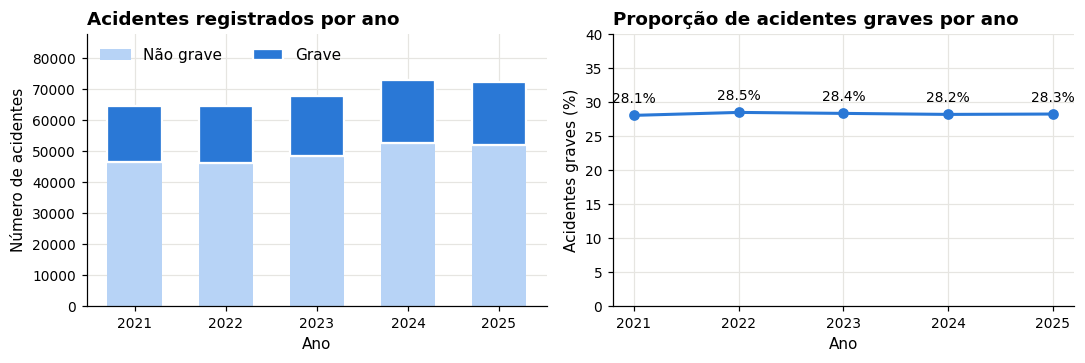

,acidentes,graves,proporcao
ano,,,
2021,64567,18118,0.281
2022,64606,18409,0.285
2023,67766,19212,0.284
2024,73202,20644,0.282
2025,72529,20493,0.283


In [35]:
por_ano = dados.groupby("ano")["grave"].agg(acidentes="size", graves="sum", proporcao="mean")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ax1.bar(por_ano.index, por_ano["acidentes"] - por_ano["graves"], color="#b7d3f6", label="Não grave", width=0.6)
ax1.bar(por_ano.index, por_ano["graves"], bottom=por_ano["acidentes"] - por_ano["graves"], color=AZUL,
        label="Grave", width=0.6, edgecolor="white", linewidth=1.5)
ax1.set_title("Acidentes registrados por ano")
ax1.set_ylabel("Número de acidentes")
ax1.set_xlabel("Ano")
ax1.legend(loc="upper left", ncol=2)
ax1.set_ylim(0, por_ano["acidentes"].max() * 1.2)

ax2.plot(por_ano.index, por_ano["proporcao"] * 100, color=AZUL, marker="o", linewidth=2)
for ano, p in por_ano["proporcao"].items():
    ax2.annotate(f"{p*100:.1f}%", (ano, p * 100), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax2.set_ylim(0, 40)
ax2.set_title("Proporção de acidentes graves por ano")
ax2.set_ylabel("Acidentes graves (%)")
ax2.set_xlabel("Ano")
ax2.set_xticks(por_ano.index)
plt.tight_layout()
plt.show()
por_ano

**Leitura.** O número de acidentes registrados cresceu de cerca de 64,6 mil em 2021 para 73,2 mil em 2024, mas a proporção de graves ficou praticamente constante, entre 28,1% e 28,5%. Duas consequências: (i) o problema é **desbalanceado** (cerca de 28% de positivos), o que pede métricas próprias e não acurácia; (ii) a distribuição do rótulo não muda entre os anos, então diferenças de desempenho entre treino e teste não poderão ser atribuídas a mudança na taxa base.

### 5.2 Em que horários os acidentes são mais graves?

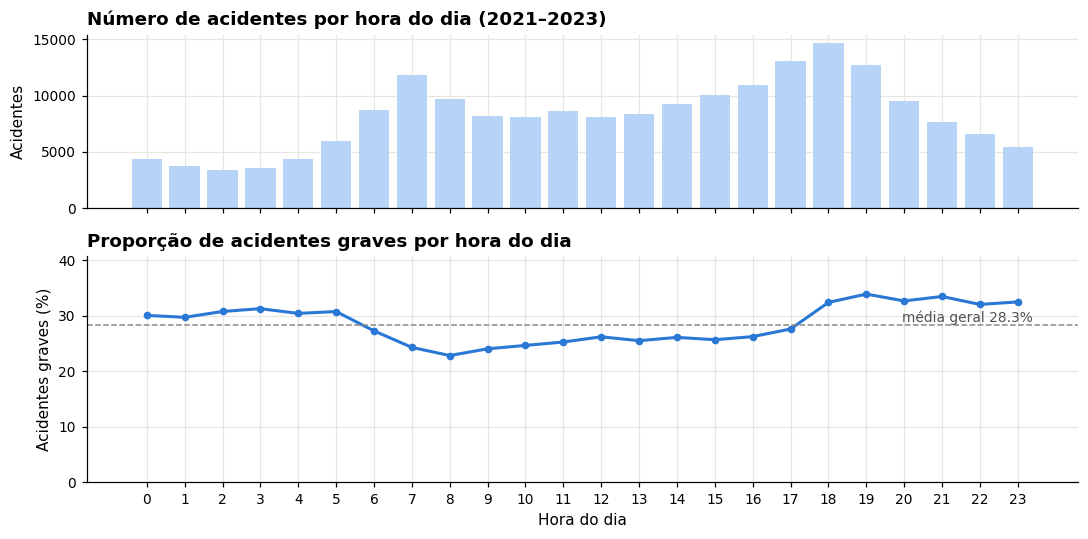

In [36]:
dados["hora_cheia"] = dados["hora"].astype(int)
exploracao = dados[dados["ano"] <= 2023]          # apenas os anos de treino
por_hora = exploracao.groupby("hora_cheia")["grave"].agg(acidentes="size", proporcao="mean")
media_geral = exploracao["grave"].mean() * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ax1.bar(por_hora.index, por_hora["acidentes"], color="#b7d3f6", width=0.8)
ax1.set_title("Número de acidentes por hora do dia (2021–2023)")
ax1.set_ylabel("Acidentes")
ax2.plot(por_hora.index, por_hora["proporcao"] * 100, color=AZUL, marker="o", linewidth=2, markersize=4)
ax2.axhline(media_geral, color=CINZA, linestyle="--", linewidth=1)
ax2.text(23.4, media_geral + 0.6, f"média geral {media_geral:.1f}%", ha="right", fontsize=9, color="#52514e")
ax2.set_title("Proporção de acidentes graves por hora do dia")
ax2.set_ylabel("Acidentes graves (%)")
ax2.set_xlabel("Hora do dia")
ax2.set_xticks(range(0, 24))
ax2.set_ylim(0, por_hora["proporcao"].max() * 100 * 1.2)
plt.tight_layout()
plt.show()

**Leitura.** O volume e a gravidade seguem padrões opostos. O número de acidentes tem dois picos, às 7h e às 18h, que coincidem com os horários de maior tráfego. Já a proporção de graves é mais baixa justamente de manhã (cerca de 23% às 8h) e mais alta à noite (cerca de 34% às 19h, e em torno de 30% durante a madrugada). Uma explicação plausível é que tráfego intenso reduz a velocidade e produz mais colisões leves, enquanto à noite há menos visibilidade e velocidades maiores. A diferença existe, mas é de poucos pontos percentuais: a hora sozinha não separa bem as classes.

### 5.3 Quais condições da via e do ambiente se associam à gravidade?

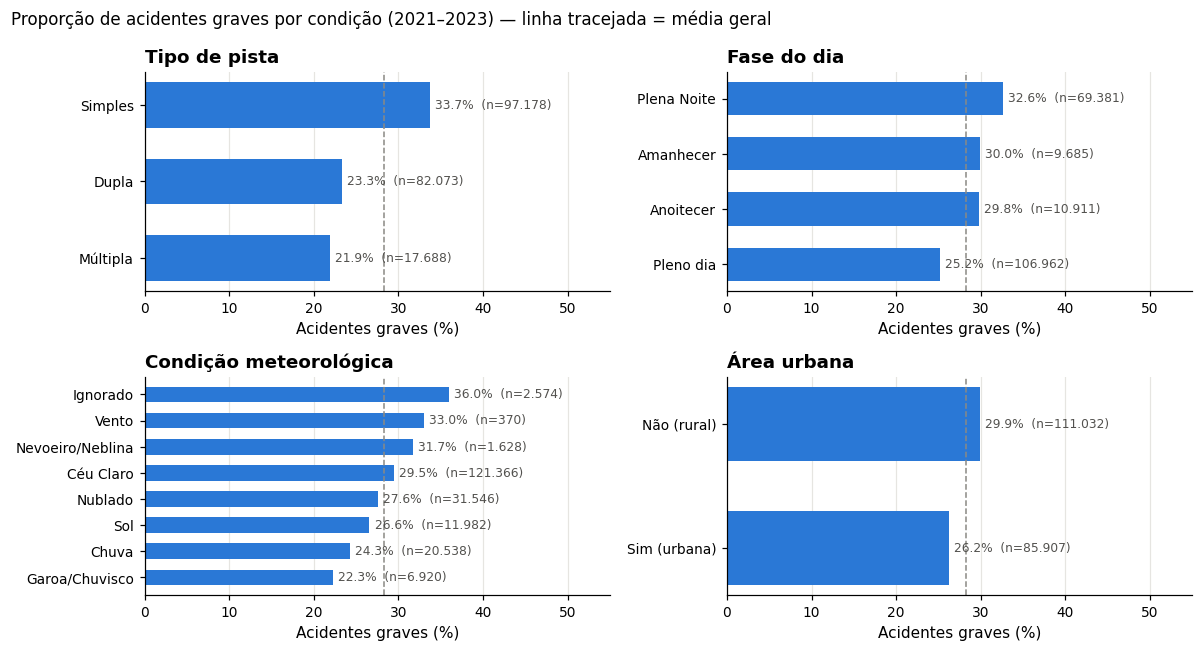

In [37]:
def taxa_por_categoria(coluna, minimo=300):
    t = exploracao.groupby(coluna)["grave"].agg(acidentes="size", proporcao="mean")
    return t[t["acidentes"] >= minimo].sort_values("proporcao")


paineis = [("tipo_pista", "Tipo de pista"), ("fase_dia", "Fase do dia"),
           ("condicao_metereologica", "Condição meteorológica"), ("area_urbana", "Área urbana")]
fig, eixos = plt.subplots(2, 2, figsize=(11, 6))
for ax, (coluna, titulo) in zip(eixos.ravel(), paineis):
    t = taxa_por_categoria(coluna)
    rotulos = t.index.map({0: "Não (rural)", 1: "Sim (urbana)"}) if coluna == "area_urbana" else t.index
    ax.barh(rotulos, t["proporcao"] * 100, color=AZUL, height=0.6)
    ax.axvline(media_geral, color=CINZA, linestyle="--", linewidth=1)
    for y, (p, n) in enumerate(zip(t["proporcao"], t["acidentes"])):
        ax.text(p * 100 + 0.6, y, f"{p*100:.1f}%  (n={n:,})".replace(",", "."), va="center", fontsize=8, color="#52514e")
    ax.set_xlim(0, 55)
    ax.set_title(titulo)
    ax.set_xlabel("Acidentes graves (%)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Proporção de acidentes graves por condição (2021–2023) — linha tracejada = média geral", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

**Leitura.**
- **Tipo de pista** é o fator de contexto com maior diferença: 33,7% de graves em pista simples contra 23,3% em pista dupla e 21,9% em múltipla. Em pista simples não há separação física entre os sentidos, o que permite colisões frontais.
- **Fase do dia**: 32,6% em plena noite contra 25,2% em pleno dia, coerente com o gráfico por hora.
- **Clima**: o resultado contraria a intuição. Com chuva (24,3%) e garoa (22,3%) a proporção de graves é *menor* do que com céu claro (29,5%). Isso não significa que chuva é segura: a base só tem acidentes ocorridos, e na chuva acontecem muitos acidentes leves (derrapagens, colisões traseiras em baixa velocidade), que diluem a proporção. É um exemplo de por que o modelo estima gravidade *dado o acidente*, e não risco de acidente.
- **Área urbana**: 26,2% contra 29,9% em área rural, onde as velocidades são maiores e o socorro demora mais.
- A categoria "Ignorado" do clima tem a maior proporção (36,0%), o que justifica mantê-la como categoria em vez de descartar as linhas.

Todas as diferenças são moderadas. Nenhum atributo de contexto, isoladamente, leva a proporção de graves muito além de um terço.

### 5.4 A gravidade varia entre os estados?

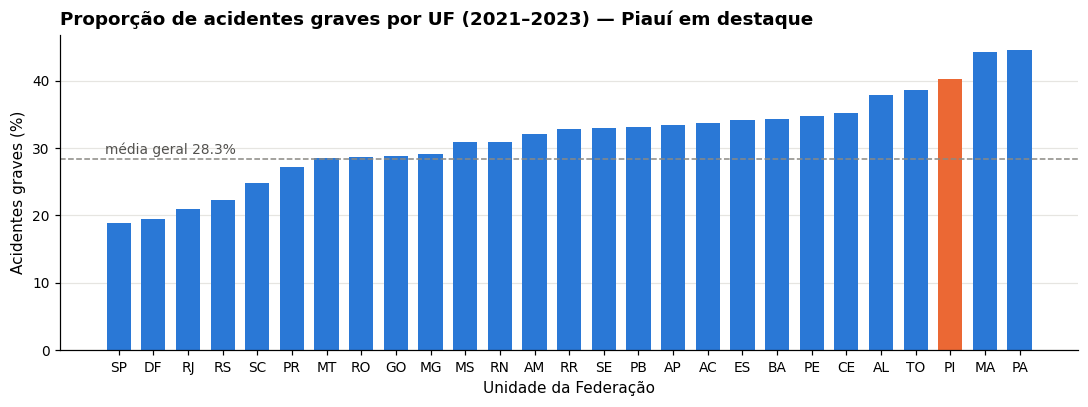

,acidentes,proporcao
regiao,,
Sul,59537,0.251
Sudeste,60973,0.255
Centro-Oeste,23963,0.281
Norte,10627,0.350
Nordeste,41839,0.355


In [38]:
por_uf = exploracao.groupby("uf")["grave"].agg(acidentes="size", proporcao="mean").sort_values("proporcao")
cores = [LARANJA if uf == "PI" else AZUL for uf in por_uf.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(por_uf.index, por_uf["proporcao"] * 100, color=cores, width=0.7)
ax.axhline(media_geral, color=CINZA, linestyle="--", linewidth=1)
ax.text(-0.4, media_geral + 0.8, f"média geral {media_geral:.1f}%", fontsize=9, color="#52514e")
ax.set_title("Proporção de acidentes graves por UF (2021–2023) — Piauí em destaque")
ax.set_ylabel("Acidentes graves (%)")
ax.set_xlabel("Unidade da Federação")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

por_regiao = exploracao.groupby("regiao")["grave"].agg(acidentes="size", proporcao="mean").sort_values("proporcao")
por_regiao

**Leitura.** A variação entre estados é a maior encontrada na análise exploratória: de cerca de 19% em São Paulo e no Distrito Federal a mais de 40% no Piauí, Pará e Maranhão. Por região, Sul (25,1%) e Sudeste (25,5%) ficam abaixo da média, e Norte (35,0%) e Nordeste (35,5%) bem acima.

Essa diferença tem pelo menos duas explicações possíveis, que os dados não permitem separar: (i) diferenças reais de infraestrutura (mais pista simples, maior distância até o atendimento hospitalar); (ii) diferenças de registro, se acidentes leves forem menos registrados onde há menos efetivo. A consequência para a modelagem é que a localização será um atributo forte, e que o modelo pode acabar aprendendo "em que estado ocorreu" em vez de características do acidente. A Seção 10.1 verifica isso.

### 5.5 O tipo de acidente explica a gravidade? E o preenchimento da base mudou com o tempo?

O tipo de acidente não é contexto: só existe depois que o acidente acontece. Ainda assim vale olhar, porque os trabalhos relacionados o usam como atributo.

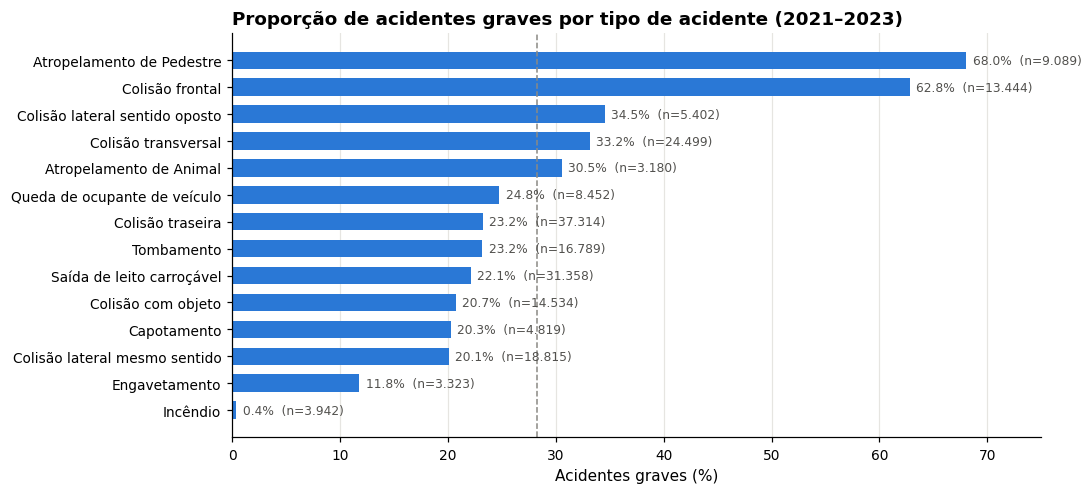

,tracado_via com mais de um valor (%),causas distintas,tipos distintos
ano,,,
2021,9.900,71,17
2022,11.700,71,16
2023,24.400,75,16
2024,25.200,69,17
2025,25.800,69,17


In [39]:
t = taxa_por_categoria("tipo_acidente", minimo=1000)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(t.index, t["proporcao"] * 100, color=AZUL, height=0.65)
ax.axvline(media_geral, color=CINZA, linestyle="--", linewidth=1)
for y, (p, n) in enumerate(zip(t["proporcao"], t["acidentes"])):
    ax.text(p * 100 + 0.6, y, f"{p*100:.1f}%  (n={n:,})".replace(",", "."), va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 75)
ax.set_title("Proporção de acidentes graves por tipo de acidente (2021–2023)")
ax.set_xlabel("Acidentes graves (%)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

mudanca = pd.DataFrame({
    "tracado_via com mais de um valor (%)": bruto.groupby("ano")["tracado_via"].apply(lambda s: s.str.contains(";").mean() * 100),
    "causas distintas": bruto.groupby("ano")["causa_acidente"].nunique(),
    "tipos distintos": bruto.groupby("ano")["tipo_acidente"].nunique(),
})
mudanca.round(1)

**Leitura.** O tipo de acidente separa as classes muito mais do que qualquer atributo de contexto: 68,0% dos atropelamentos de pedestre e 62,8% das colisões frontais são graves, contra 11,8% dos engavetamentos e 0,4% dos incêndios. Isso antecipa o resultado da Seção 8.2: modelos que usam o tipo do acidente terão desempenho melhor, mas essa informação só existe depois do fato.

A tabela mostra uma mudança no preenchimento: a fração de registros com mais de um valor em `tracado_via` passou de cerca de 10% em 2021–2022 para cerca de 25% a partir de 2023. O conjunto de causas e tipos também varia de um ano para outro. É uma mudança na forma de registrar, não nas rodovias, e é um motivo concreto para avaliar o modelo em anos posteriores ao treino.

## 6. Protocolo experimental

**Divisão temporal.** O uso pretendido é prever acidentes *futuros* com um modelo treinado no passado. A divisão segue essa ordem:

| Conjunto | Anos | Papel |
|---|---|---|
| **Treino** | 2021, 2022, 2023 | Ajuste dos modelos e do pré-processamento. |
| **Validação** | 2024 | Escolha de hiperparâmetros e do limiar de decisão. |
| **Teste** | 2025 | Avaliação final. Só é consultado depois de todas as escolhas feitas. |

Uma divisão aleatória misturaria acidentes de todos os anos em treino e teste e poderia esconder mudanças na forma de registro (Seção 5.5). A Seção 9 compara as duas divisões para medir essa diferença.

**Prevenção de vazamento.** Três cuidados:
1. *Vazamento de rótulo*: as colunas de desfecho nunca entram como atributo no modelo principal.
2. *Vazamento de pré-processamento*: padronização e codificação ficam dentro de um `Pipeline` do scikit-learn, ajustado apenas com o treino. Validação e teste só são transformados.
3. *Vazamento por seleção*: hiperparâmetros e limiar são escolhidos na validação; o teste não participa de nenhuma decisão.

**Três conjuntos de atributos.** Para responder à pergunta de pesquisa, os mesmos modelos são treinados com três conjuntos:

| Cenário | Atributos | Quando a informação existe |
|---|---|---|
| **A — Contexto** (principal) | Local, horário, clima, tipo e traçado da pista | Antes do acidente, ou no momento do chamado. |
| **B — Contexto + dinâmica** | A + tipo e causa do acidente, nº de veículos e de pessoas | Depois do acidente, quando alguém o descreve. |
| **C — Com vazamento** | B + classificação do acidente, feridos leves, ilesos, ignorados | Só depois de contadas as vítimas, ou seja, quando o desfecho já é conhecido. |

In [40]:
NUM_A = ["hora", "hora_sen", "hora_cos", "mes", "fim_de_semana", "km", "latitude", "longitude", "area_urbana"] \
        + list(NOME_TRACADO.values())
CAT_A = ["dia_semana", "fase_dia", "uf", "br", "sentido_via", "condicao_metereologica", "tipo_pista"]
NUM_B, CAT_B = NUM_A + ["veiculos", "pessoas"], CAT_A + ["tipo_acidente", "causa_acidente"]
NUM_C, CAT_C = NUM_B + ["feridos_leves", "ilesos", "ignorados"], CAT_B + ["classificacao_acidente"]
CENARIOS = {"A — Contexto": (NUM_A, CAT_A), "B — Contexto + dinâmica": (NUM_B, CAT_B), "C — Com vazamento": (NUM_C, CAT_C)}

treino = dados[dados["ano"] <= 2023]
validacao = dados[dados["ano"] == 2024]
teste = dados[dados["ano"] == 2025]
y_treino, y_validacao, y_teste = treino["grave"], validacao["grave"], teste["grave"]

pd.DataFrame({
    "acidentes": [len(treino), len(validacao), len(teste)],
    "graves (%)": [y_treino.mean() * 100, y_validacao.mean() * 100, y_teste.mean() * 100],
}, index=["treino (2021–2023)", "validação (2024)", "teste (2025)"]).round(1)

,acidentes,graves (%)
treino (2021–2023),196939,28.300
validação (2024),73202,28.200
teste (2025),72529,28.300


### 6.1 Métricas

A classe grave é minoria (cerca de 28%). Um modelo que respondesse sempre "não grave" teria cerca de 72% de acurácia sem detectar nenhum caso grave. Por isso a acurácia é reportada apenas como referência, e a avaliação se apoia em:

- **PR-AUC** (área sob a curva precisão–revocação, *average precision*): métrica principal. Resume a qualidade do ordenamento por risco sem depender de um limiar, e sua linha de base é a própria proporção de graves. É a métrica usada para escolher hiperparâmetros.
- **ROC-AUC**: probabilidade de o modelo dar nota maior a um acidente grave do que a um não grave. Linha de base 0,5.
- **Revocação** (*recall*) da classe grave: fração dos acidentes graves que o modelo aponta. É o erro mais custoso na aplicação (deixar de priorizar um caso grave).
- **Precisão**: fração dos alertas que eram de fato graves. Mede o custo de alarmes falsos.
- **F1**: média harmônica de precisão e revocação, usada para fixar o limiar de decisão na validação.

In [41]:
def preprocessador(numericas, categoricas):
    return ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), categoricas),
    ])


def montar(modelo, numericas, categoricas):
    """Pipeline = pré-processamento + modelo. Tudo é ajustado junto, só com os dados de treino."""
    return Pipeline([("prep", preprocessador(numericas, categoricas)), ("modelo", modelo)])


def melhor_limiar(y, prob):
    """Limiar que maximiza o F1 da classe grave. Deve ser chamado apenas com dados de validação."""
    precisao, revocacao, limiares = precision_recall_curve(y, prob)
    f1 = 2 * precisao * revocacao / np.clip(precisao + revocacao, 1e-12, None)
    return float(limiares[np.argmax(f1[:-1])])


def avaliar(y, prob, limiar):
    previsto = (prob >= limiar).astype(int)
    return {
        "PR-AUC": average_precision_score(y, prob),
        "ROC-AUC": roc_auc_score(y, prob) if len(np.unique(prob)) > 1 else 0.5,
        "F1": f1_score(y, previsto, zero_division=0),
        "Precisão": precision_score(y, previsto, zero_division=0),
        "Revocação": recall_score(y, previsto, zero_division=0),
        "Acurácia": accuracy_score(y, previsto),
    }


def prob_grave(modelo, X):
    return modelo.predict_proba(X)[:, 1]

## 7. Modelagem

**Referências (baselines).**
- *Sempre não grave*: prevê a classe majoritária. Mostra por que a acurácia engana.
- *Sempre grave*: marca tudo como grave. Tem revocação 100% e define o F1 mínimo que qualquer modelo útil precisa superar.
- **Regressão logística**: modelo linear, rápido e interpretável. É a referência "séria": se um modelo mais complexo não a supera, a complexidade não se justifica.

**Abordagem principal: Random Forest.** Conjunto de árvores de decisão treinadas em amostras diferentes dos dados. Foi escolhida porque (i) captura interações e relações não lineares que o modelo linear não vê, como "pista simples **e** noite **e** área rural"; (ii) lida bem com atributos em escalas diferentes; (iii) é o algoritmo mais usado nos trabalhos relacionados com dados da PRF, o que permite comparação direta.

**Desbalanceamento.** Os dois modelos usam `class_weight="balanced"`, que dá mais peso aos erros na classe grave em vez de criar exemplos sintéticos. É mais simples que SMOTE e não altera os dados.

**Hiperparâmetros.** Uma busca pequena em grade, avaliada na validação (2024) pela PR-AUC, no cenário A. Os valores escolhidos são reutilizados nos cenários B e C para que a única diferença entre cenários sejam os atributos.

In [42]:
X_tr, X_va = treino[NUM_A + CAT_A], validacao[NUM_A + CAT_A]
busca = []

# --- Regressão logística: C controla a regularização (menor = mais regularizado)
for C in [0.01, 0.1, 1.0]:
    inicio = time.time()
    m = montar(LogisticRegression(C=C, class_weight="balanced", max_iter=1000), NUM_A, CAT_A).fit(X_tr, y_treino)
    busca.append({"modelo": "Regressão logística", "hiperparâmetros": f"C={C}",
                  "PR-AUC treino": average_precision_score(y_treino, prob_grave(m, X_tr)),
                  "PR-AUC validação": average_precision_score(y_validacao, prob_grave(m, X_va)),
                  "tempo (s)": time.time() - inicio, "_params": {"C": C}})

# --- Random Forest: profundidade máxima e tamanho mínimo da folha controlam a complexidade
for profundidade in [12, None]:
    for folha in [20, 50]:
        inicio = time.time()
        rf = RandomForestClassifier(n_estimators=100, max_samples=0.5, max_depth=profundidade, min_samples_leaf=folha,
                                    max_features="sqrt", class_weight="balanced", n_jobs=-1, random_state=SEMENTE)
        m = montar(rf, NUM_A, CAT_A).fit(X_tr, y_treino)
        busca.append({"modelo": "Random Forest", "hiperparâmetros": f"max_depth={profundidade}, min_samples_leaf={folha}",
                      "PR-AUC treino": average_precision_score(y_treino, prob_grave(m, X_tr)),
                      "PR-AUC validação": average_precision_score(y_validacao, prob_grave(m, X_va)),
                      "tempo (s)": time.time() - inicio,
                      "_params": {"max_depth": profundidade, "min_samples_leaf": folha}})

busca = pd.DataFrame(busca)
busca.drop(columns="_params").round(4)

,modelo,hiperparâmetros,PR-AUC treino,PR-AUC validação,tempo (s)
0,Regressão logística,C=0.01,0.393,0.397,5.171
1,Regressão logística,C=0.1,0.394,0.397,7.905
2,Regressão logística,C=1.0,0.394,0.397,7.801
3,Random Forest,"max_depth=12, min_samples_leaf=20",0.417,0.400,50.345
4,Random Forest,"max_depth=12, min_samples_leaf=50",0.408,0.401,47.958
5,Random Forest,"max_depth=None, min_samples_leaf=20",0.468,0.404,115.765
6,Random Forest,"max_depth=None, min_samples_leaf=50",0.427,0.402,84.746


In [43]:
melhor = busca.loc[busca.groupby("modelo")["PR-AUC validação"].idxmax()].set_index("modelo")
PARAMS_LR = melhor.loc["Regressão logística", "_params"]
PARAMS_RF = melhor.loc["Random Forest", "_params"]
print("Regressão logística escolhida:", PARAMS_LR)
print("Random Forest escolhida:      ", PARAMS_RF)


def nova_logistica():
    return LogisticRegression(**PARAMS_LR, class_weight="balanced", max_iter=1000)


def nova_floresta(semente=SEMENTE):
    return RandomForestClassifier(n_estimators=100, max_samples=0.5, **PARAMS_RF, max_features="sqrt",
                                  class_weight="balanced", n_jobs=-1, random_state=semente)

Regressão logística escolhida: {'C': 0.1}
Random Forest escolhida:       {'max_depth': None, 'min_samples_leaf': 20}


**Leitura.**
- Na **regressão logística**, a regularização praticamente não altera o resultado (PR-AUC de validação 0,397 nos três valores de `C`). O modelo linear já está no limite do que consegue extrair desses atributos.
- Na **Random Forest**, as quatro configurações ficam entre 0,400 e 0,404 na validação. A melhor é a de árvores sem limite de profundidade com folhas de pelo menos 20 acidentes.
- A diferença entre treino e validação mostra o grau de **sobreajuste**: a configuração escolhida tem 0,468 no treino e 0,404 na validação. Árvores mais rasas reduzem essa diferença, mas não melhoram a validação.
- O ganho da Random Forest sobre a regressão logística na validação é de menos de 0,01. O resultado é pouco sensível aos hiperparâmetros, o que indica que o limite está na **informação contida nos atributos**, não na capacidade do modelo.

Para manter o tempo de execução viável no Colab, a floresta usa 100 árvores, cada uma treinada com metade das linhas de treino (`max_samples=0.5`).

## 8. Avaliação no conjunto de teste (2025)

Com os hiperparâmetros fixados, cada modelo é treinado em 2021–2023, tem o limiar de decisão definido em 2024 e é avaliado **uma única vez** em 2025.

### 8.1 Cenário A — modelo principal e baselines

In [44]:
resultados, modelos, limiares, probs_teste = [], {}, {}, {}


def treinar_e_avaliar(nome, estimador, cenario):
    numericas, categoricas = CENARIOS[cenario]
    colunas = numericas + categoricas
    m = montar(estimador, numericas, categoricas).fit(treino[colunas], y_treino)
    limiar = melhor_limiar(y_validacao, prob_grave(m, validacao[colunas]))
    prob = prob_grave(m, teste[colunas])
    chave = (cenario, nome)
    modelos[chave], limiares[chave], probs_teste[chave] = m, limiar, prob
    resultados.append({"cenário": cenario, "modelo": nome, "limiar": limiar, **avaliar(y_teste, prob, limiar)})


CEN_A = "A — Contexto"
# Baselines triviais: probabilidade constante; o limiar decide se tudo vira "grave" ou "não grave"
constante = np.full(len(teste), y_treino.mean())
resultados.append({"cenário": CEN_A, "modelo": "Sempre não grave", "limiar": 1.0, **avaliar(y_teste, constante, 1.0)})
resultados.append({"cenário": CEN_A, "modelo": "Sempre grave", "limiar": 0.0, **avaliar(y_teste, constante, 0.0)})
treinar_e_avaliar("Regressão logística", nova_logistica(), CEN_A)
treinar_e_avaliar("Random Forest", nova_floresta(), CEN_A)

tabela_a = pd.DataFrame(resultados).set_index("modelo").drop(columns="cenário")
tabela_a.round(3)

,limiar,PR-AUC,ROC-AUC,F1,Precisão,Revocação,Acurácia
modelo,,,,,,,
Sempre não grave,1.000,0.283,0.500,0.000,0.000,0.000,0.717
Sempre grave,0.000,0.283,0.500,0.441,0.283,1.000,0.283
Regressão logística,0.423,0.386,0.620,0.460,0.321,0.810,0.463
Random Forest,0.427,0.395,0.627,0.465,0.331,0.783,0.491


O limiar acima transforma a nota em um "sim ou não". Outra forma de usar o modelo é como **ordenador de prioridade**: olhar apenas a fração dos acidentes com maior risco previsto. A tabela mostra, para a Random Forest, quantos dos acidentes priorizados eram de fato graves.

In [45]:
ordenado = teste.assign(prob=probs_teste[(CEN_A, "Random Forest")]).sort_values("prob", ascending=False)
linhas = []
for fracao in [0.05, 0.10, 0.20, 0.50]:
    topo = ordenado.head(int(len(ordenado) * fracao))
    linhas.append({"acidentes priorizados": f"{fracao*100:.0f}% de maior risco", "quantidade": len(topo),
                   "graves entre os priorizados (%)": topo["grave"].mean() * 100,
                   "vezes a taxa base": topo["grave"].mean() / y_teste.mean(),
                   "graves capturados (%)": topo["grave"].sum() / y_teste.sum() * 100})
pd.DataFrame(linhas).set_index("acidentes priorizados").round(2)

,quantidade,graves entre os priorizados (%),vezes a taxa base,graves capturados (%)
acidentes priorizados,,,,
5% de maior risco,3626,51.430,1.820,9.100
10% de maior risco,7252,46.910,1.660,16.600
20% de maior risco,14505,42.290,1.500,29.930
50% de maior risco,36264,35.430,1.250,62.690


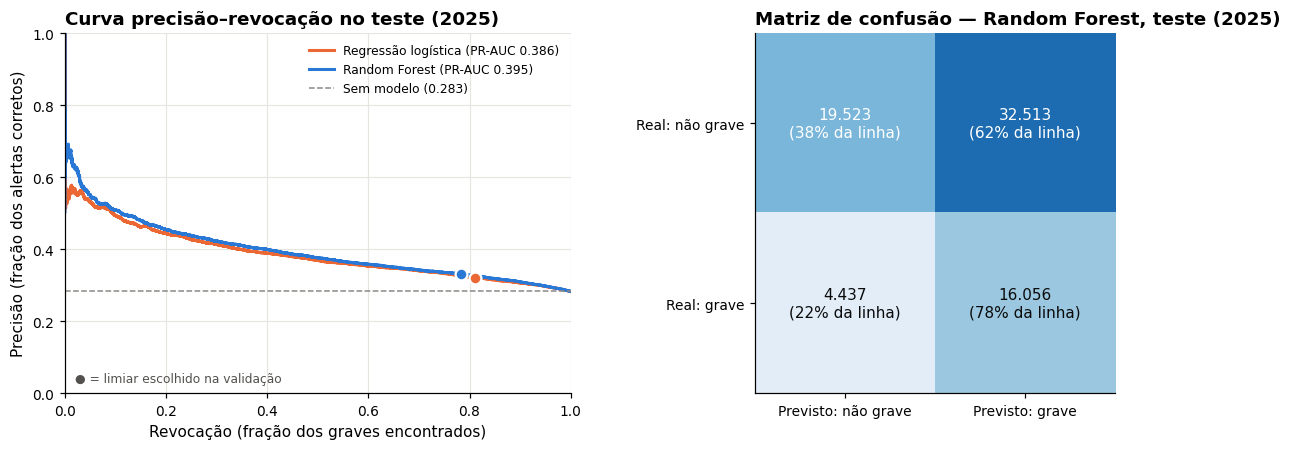

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

for nome, cor in [("Regressão logística", LARANJA), ("Random Forest", AZUL)]:
    prob = probs_teste[(CEN_A, nome)]
    precisao, revocacao, _ = precision_recall_curve(y_teste, prob)
    ax1.plot(revocacao, precisao, color=cor, linewidth=2, label=f"{nome} (PR-AUC {average_precision_score(y_teste, prob):.3f})")
    previsto = prob >= limiares[(CEN_A, nome)]
    ax1.scatter(recall_score(y_teste, previsto), precision_score(y_teste, previsto), color=cor, s=60, zorder=3,
                edgecolor="white", linewidth=1.5)
ax1.axhline(y_teste.mean(), color=CINZA, linestyle="--", linewidth=1, label=f"Sem modelo ({y_teste.mean():.3f})")
ax1.set_title("Curva precisão–revocação no teste (2025)")
ax1.set_xlabel("Revocação (fração dos graves encontrados)")
ax1.set_ylabel("Precisão (fração dos alertas corretos)")
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.legend(loc="upper right", fontsize=8)
ax1.text(0.02, 0.03, "● = limiar escolhido na validação", transform=ax1.transAxes, fontsize=8, color="#52514e")

matriz = confusion_matrix(y_teste, probs_teste[(CEN_A, "Random Forest")] >= limiares[(CEN_A, "Random Forest")])
ax2.imshow(matriz, cmap="Blues", vmin=0, vmax=matriz.max() * 1.3)
for i in range(2):
    for j in range(2):
        ax2.text(j, i, f"{matriz[i, j]:,}".replace(",", ".") + f"\n({matriz[i, j] / matriz[i].sum() * 100:.0f}% da linha)",
                 ha="center", va="center", fontsize=10, color="white" if matriz[i, j] > matriz.max() * 0.6 else "#0b0b0b")
ax2.set_xticks([0, 1], ["Previsto: não grave", "Previsto: grave"])
ax2.set_yticks([0, 1], ["Real: não grave", "Real: grave"])
ax2.set_title("Matriz de confusão — Random Forest, teste (2025)")
ax2.grid(False)
plt.tight_layout()
plt.show()

**Leitura.**
- **O contexto tem sinal, mas fraco.** A Random Forest atinge PR-AUC de 0,395 no teste, contra 0,283 de um ordenamento ao acaso (1,4 vez a linha de base), e ROC-AUC de 0,627. Há informação real nos atributos de contexto, porém longe de uma separação confiável.
- **A acurácia engana nos dois sentidos.** "Sempre não grave" tem a maior acurácia da tabela (0,717) sem detectar um único caso grave. A Random Forest tem acurácia de 0,491 e ainda assim é o melhor modelo nas métricas que importam.
- **O limiar que maximiza o F1 é quase "alertar tudo".** O F1 da Random Forest (0,465) supera por pouco o de marcar todos os acidentes como graves (0,441). A matriz de confusão mostra o motivo: para encontrar 78% dos acidentes graves, o modelo marca como grave 62% dos não graves. Como classificador de "sim ou não", o modelo de contexto não é útil na prática.
- **Como ordenador de prioridade, o ganho é modesto, mas existe.** Entre os 10% de acidentes com maior risco previsto, 46,9% são graves (1,7 vez a taxa base de 28,3%), e esses 10% concentram 16,6% de todos os acidentes graves. Entre os 20% de maior risco, 42,3% são graves.
- A Random Forest supera a regressão logística por cerca de 0,01 em PR-AUC. A Seção 9.2 verifica se essa diferença é maior que a variação amostral.

### 8.2 Auditoria de vazamento — cenários A, B e C

Os mesmos dois modelos, com os mesmos hiperparâmetros, são treinados agora com os atributos dos cenários B e C. A única coisa que muda é a informação disponível.

In [47]:
for cenario in ["B — Contexto + dinâmica", "C — Com vazamento"]:
    treinar_e_avaliar("Regressão logística", nova_logistica(), cenario)
    treinar_e_avaliar("Random Forest", nova_floresta(), cenario)

tabela_cenarios = pd.DataFrame(resultados)
tabela_cenarios = tabela_cenarios[tabela_cenarios["modelo"].isin(["Regressão logística", "Random Forest"])]
tabela_cenarios = tabela_cenarios.set_index(["cenário", "modelo"]).drop(columns="limiar")
tabela_cenarios.round(3)

PR-AUC  ROC-AUC    F1  Precisão  \
cenário                 modelo                                                 
A — Contexto            Regressão logística   0.386    0.620 0.460     0.321   
                        Random Forest         0.395    0.627 0.465     0.331   
B — Contexto + dinâmica Regressão logística   0.522    0.713 0.509     0.436   
                        Random Forest         0.528    0.714 0.510     0.436   
C — Com vazamento       Regressão logística   0.994    0.996 0.982     0.983   
                        Random Forest         0.965    0.981 0.900     0.982   

                                             Revocação  Acurácia  
cenário                 modelo                                    
A — Contexto            Regressão logística      0.810     0.463  
                        Random Forest            0.783     0.491  
B — Contexto + dinâmica Regressão logística      0.612     0.667  
                        Random Forest            0.616     0.666  
C — Com vazamento       Regressão logística      0.982     0.990  
                        Random Forest            0.830     0.948

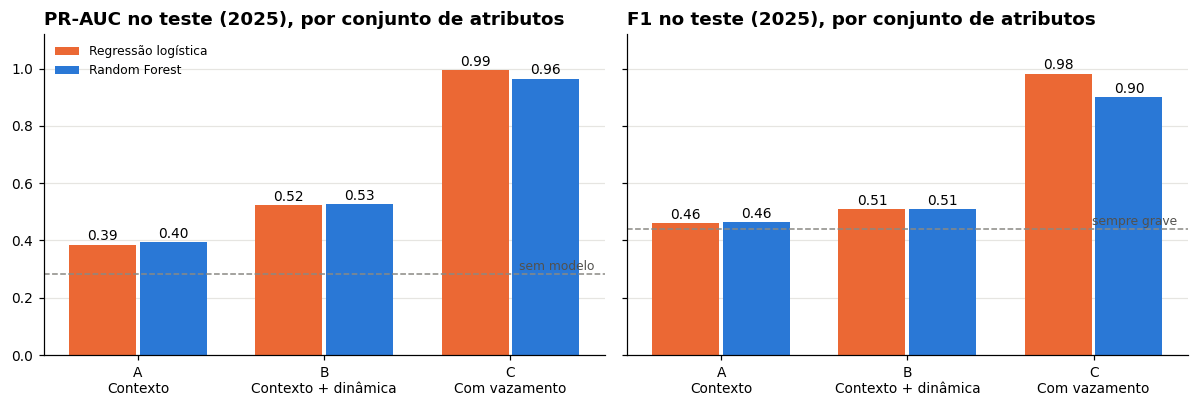

In [48]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
nomes_cenarios = list(CENARIOS)
x = np.arange(len(nomes_cenarios))
for ax, metrica in zip(eixos, ["PR-AUC", "F1"]):
    for deslocamento, (nome, cor) in zip([-0.19, 0.19], [("Regressão logística", LARANJA), ("Random Forest", AZUL)]):
        valores = [tabela_cenarios.loc[(c, nome), metrica] for c in nomes_cenarios]
        ax.bar(x + deslocamento, valores, width=0.36, color=cor, label=nome)
        for xi, v in zip(x + deslocamento, valores):
            ax.text(xi, v + 0.015, f"{v:.2f}", ha="center", fontsize=9)
    referencia = y_teste.mean() if metrica == "PR-AUC" else tabela_a.loc["Sempre grave", "F1"]
    ax.axhline(referencia, color=CINZA, linestyle="--", linewidth=1)
    ax.text(2.45, referencia + 0.015, "sem modelo" if metrica == "PR-AUC" else "sempre grave", ha="right", fontsize=8, color="#52514e")
    ax.set_xticks(x, [c.replace(" — ", "\n") for c in nomes_cenarios])
    ax.set_ylim(0, 1.12)
    ax.set_title(f"{metrica} no teste (2025), por conjunto de atributos")
    ax.grid(axis="x", visible=False)
eixos[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Leitura.** Este é o resultado central do trabalho.

- **De A para B**, a PR-AUC sobe de 0,395 para 0,528 e a ROC-AUC de 0,627 para 0,714. Saber *como* foi o acidente (tipo, causa, veículos e pessoas envolvidas) informa mais sobre a gravidade do que todo o contexto junto. Mas essas informações só existem depois do acidente: servem para triagem de uma ocorrência já descrita, não para planejamento preventivo.
- **De B para C**, a PR-AUC passa de 0,53 para 0,97–0,99 e o F1 chega a 0,98. Esse desempenho não é mérito do modelo. As colunas adicionadas são contagens de vítimas e a classificação do acidente, de onde o próprio rótulo é calculado. Um modelo treinado assim é inútil na prática, porque no momento em que essas colunas estão preenchidas o desfecho já é conhecido.
- No cenário C a regressão logística supera a Random Forest. A relação vazada é quase uma regra direta sobre poucas colunas, que o modelo linear captura de imediato, enquanto cada árvore da floresta sorteia apenas parte dos atributos a cada divisão e nem sempre vê as colunas decisivas.

**Implicação.** Resultados muito altos em bases de acidentes devem ser lidos com cuidado: é preciso conferir quais colunas entraram como atributo e em que momento cada uma passa a existir. A diferença entre 0,40 e 0,99 nesta mesma base vem inteiramente da escolha dos atributos.

## 9. Robustez

### 9.1 Divisão temporal × divisão aleatória

Muitos trabalhos dividem treino e teste por sorteio. Para medir o efeito dessa escolha, o experimento abaixo usa **exatamente as mesmas linhas** (2021–2023 e 2025) e os mesmos tamanhos de treino e teste, mudando apenas o critério de divisão. O limiar é o mesmo definido na validação de 2024.

In [49]:
conjunto = pd.concat([treino, teste])
tr_aleatorio, te_aleatorio = train_test_split(conjunto, test_size=len(teste), stratify=conjunto["grave"], random_state=SEMENTE)
colunas_a = NUM_A + CAT_A
comparacao = []
for nome, fabrica in [("Regressão logística", nova_logistica), ("Random Forest", nova_floresta)]:
    m = montar(fabrica(), NUM_A, CAT_A).fit(tr_aleatorio[colunas_a], tr_aleatorio["grave"])
    limiar = limiares[(CEN_A, nome)]
    aleatoria = avaliar(te_aleatorio["grave"], prob_grave(m, te_aleatorio[colunas_a]), limiar)
    temporal = avaliar(y_teste, probs_teste[(CEN_A, nome)], limiar)
    for metrica in ["PR-AUC", "ROC-AUC", "F1"]:
        comparacao.append({"modelo": nome, "métrica": metrica, "divisão temporal": temporal[metrica],
                           "divisão aleatória": aleatoria[metrica], "diferença": aleatoria[metrica] - temporal[metrica]})
pd.DataFrame(comparacao).set_index(["modelo", "métrica"]).round(4)

divisão temporal  divisão aleatória  diferença
modelo              métrica                                                
Regressão logística PR-AUC              0.386              0.390      0.004
                    ROC-AUC             0.620              0.623      0.003
                    F1                  0.460              0.462      0.002
Random Forest       PR-AUC              0.395              0.400      0.005
                    ROC-AUC             0.627              0.632      0.005
                    F1                  0.465              0.465      0.000

### 9.2 Estabilidade entre sementes e incerteza da estimativa

A Random Forest tem componentes aleatórios (amostragem das linhas e dos atributos). Ela é treinada com três sementes diferentes para verificar se o resultado depende da semente. Além disso, o intervalo de confiança da PR-AUC no teste é estimado por *bootstrap* (reamostragem dos acidentes de 2025 com reposição, 500 vezes), o que indica se a diferença entre os modelos é maior que a variação amostral.

In [50]:
sementes = [42, 7, 123]
estabilidade = []
for s in sementes:
    if s == SEMENTE:
        prob = probs_teste[(CEN_A, "Random Forest")]
    else:
        m = montar(nova_floresta(s), NUM_A, CAT_A).fit(treino[colunas_a], y_treino)
        prob = prob_grave(m, teste[colunas_a])
    estabilidade.append({"semente": s, **avaliar(y_teste, prob, limiares[(CEN_A, "Random Forest")])})
estabilidade = pd.DataFrame(estabilidade).set_index("semente")
print("Random Forest em três sementes (teste 2025):")
print(estabilidade[["PR-AUC", "ROC-AUC", "F1", "Revocação"]].agg(["mean", "std", "min", "max"]).to_string(float_format="%.4f"))

gerador = np.random.default_rng(SEMENTE)
y_np = y_teste.to_numpy()
p_rf, p_lr = probs_teste[(CEN_A, "Random Forest")], probs_teste[(CEN_A, "Regressão logística")]
amostras = []
for _ in range(500):
    i = gerador.integers(0, len(y_np), len(y_np))
    amostras.append((average_precision_score(y_np[i], p_rf[i]), average_precision_score(y_np[i], p_lr[i])))
amostras = np.array(amostras)
diferenca = amostras[:, 0] - amostras[:, 1]
print("\nIntervalos de 95% por bootstrap (PR-AUC, teste 2025):")
print(f"  Random Forest .......... {np.percentile(amostras[:, 0], 2.5):.4f} a {np.percentile(amostras[:, 0], 97.5):.4f}")
print(f"  Regressão logística .... {np.percentile(amostras[:, 1], 2.5):.4f} a {np.percentile(amostras[:, 1], 97.5):.4f}")
print(f"  Diferença (RF − RL) .... {np.percentile(diferenca, 2.5):.4f} a {np.percentile(diferenca, 97.5):.4f}")

Random Forest em três sementes (teste 2025):
      PR-AUC  ROC-AUC     F1  Revocação
mean  0.3953   0.6269 0.4644     0.7826
std   0.0001   0.0003 0.0008     0.0025
min   0.3952   0.6266 0.4635     0.7797
max   0.3954   0.6271 0.4650     0.7846

Intervalos de 95% por bootstrap (PR-AUC, teste 2025):
  Random Forest .......... 0.3891 a 0.4014
  Regressão logística .... 0.3796 a 0.3919
  Diferença (RF − RL) .... 0.0067 a 0.0122


**Leitura.**
- **Divisão temporal × aleatória.** A divisão aleatória dá resultados ligeiramente melhores, mas a diferença é de no máximo 0,005 em PR-AUC. A hipótese inicial era que a divisão aleatória inflaria o desempenho de forma relevante, por causa da mudança de preenchimento vista na Seção 5.5. **Os dados não confirmam essa hipótese**: a relação entre contexto e gravidade se manteve estável entre 2021 e 2025. A divisão temporal continua sendo a correta para o uso pretendido, mas neste problema ela não muda a conclusão.
- **Estabilidade.** Entre três sementes, o desvio padrão da PR-AUC é 0,0001. O resultado não depende da semente.
- **Incerteza.** O intervalo de 95% da diferença entre Random Forest e regressão logística (0,007 a 0,012) não inclui zero: a floresta é consistentemente melhor. Porém a diferença é pequena em termos práticos, e a regressão logística treina em poucos segundos. Para este problema, o modelo mais simples entrega quase o mesmo resultado.

## 10. Análise de erros e interpretação

### 10.1 O modelo funciona igualmente bem em todas as regiões?

Um modelo com bom desempenho médio pode falhar em subgrupos. A tabela avalia a Random Forest do cenário A separadamente em cada região e no Piauí, com o mesmo limiar.

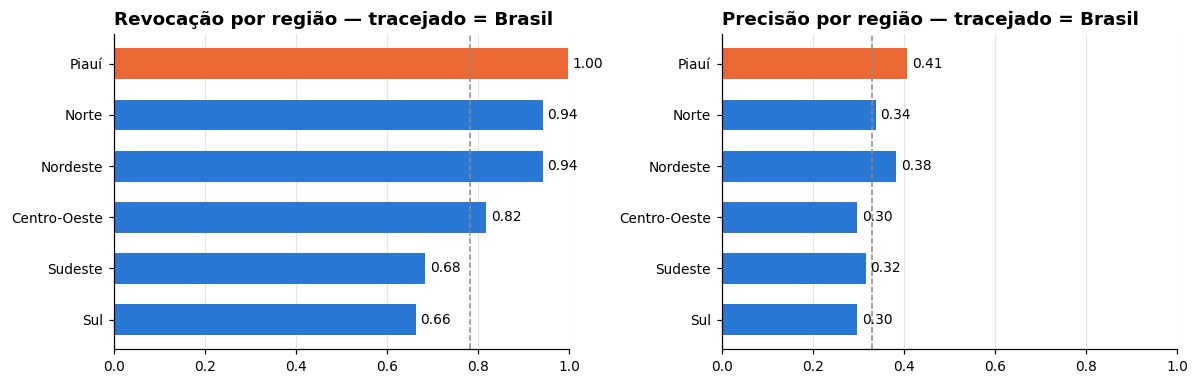

,acidentes,graves (%),PR-AUC,ganho sobre a base,ROC-AUC,Revocação,Precisão,alertas (%)
Centro-Oeste,8497,27.516,0.332,1.208,0.578,0.818,0.298,75.650
Nordeste,16019,36.076,0.480,1.330,0.632,0.943,0.383,88.757
Norte,3975,32.503,0.450,1.384,0.627,0.943,0.338,90.566
Sudeste,23323,25.173,0.347,1.377,0.625,0.684,0.316,54.418
Sul,20715,25.165,0.314,1.247,0.594,0.664,0.298,56.148
Piauí,1490,40.537,0.492,1.213,0.600,0.997,0.408,98.993
Brasil,72529,28.255,0.395,1.399,0.627,0.783,0.331,66.965


In [51]:
CHAVE = (CEN_A, "Random Forest")
analise = teste.assign(prob=probs_teste[CHAVE], previsto=(probs_teste[CHAVE] >= limiares[CHAVE]).astype(int))


def metricas_grupo(g):
    return pd.Series({"acidentes": len(g), "graves (%)": g["grave"].mean() * 100,
                      "PR-AUC": average_precision_score(g["grave"], g["prob"]),
                      "ganho sobre a base": average_precision_score(g["grave"], g["prob"]) / g["grave"].mean(),
                      "ROC-AUC": roc_auc_score(g["grave"], g["prob"]),
                      "Revocação": recall_score(g["grave"], g["previsto"]),
                      "Precisão": precision_score(g["grave"], g["previsto"], zero_division=0),
                      "alertas (%)": g["previsto"].mean() * 100})


por_grupo = pd.concat([
    pd.DataFrame({r: metricas_grupo(g) for r, g in analise.groupby("regiao")}).T,
    pd.DataFrame({"Piauí": metricas_grupo(analise[analise["uf"] == "PI"]), "Brasil": metricas_grupo(analise)}).T,
])
por_grupo["acidentes"] = por_grupo["acidentes"].astype(int)

ordem = por_grupo.drop(index="Brasil").sort_values("Revocação")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metrica in zip([ax1, ax2], ["Revocação", "Precisão"]):
    ax.barh(ordem.index, ordem[metrica], color=[LARANJA if i == "Piauí" else AZUL for i in ordem.index], height=0.6)
    ax.axvline(por_grupo.loc["Brasil", metrica], color=CINZA, linestyle="--", linewidth=1)
    for y, v in enumerate(ordem[metrica]):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_title(f"{metrica} por região — tracejado = Brasil")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
por_grupo.round(3)

**Leitura.** O desempenho médio esconde um comportamento desigual.

- Com o mesmo limiar, o modelo marca como grave **99,0% dos acidentes do Piauí**, 91% dos da região Norte e 89% dos do Nordeste, contra 54% no Sudeste e 56% no Sul. A revocação próxima de 100% no Piauí não é sinal de bom desempenho: o modelo simplesmente alerta para quase tudo o que acontece ali.
- Dentro de cada região, o ganho do modelo sobre a taxa base é menor do que no país como um todo: a PR-AUC fica entre 1,2 e 1,4 vez a proporção de graves da região, contra 1,4 no Brasil, e a ROC-AUC cai para 0,58 no Centro-Oeste e 0,59 no Sul. Parte do desempenho nacional vem de distinguir **regiões**, não acidentes.
- **Risco de viés.** Usado para priorizar atendimento, este modelo trataria toda ocorrência do Norte e do Nordeste como prioritária e deixaria de detectar cerca de um terço dos acidentes graves do Sul e do Sudeste. Usado para planejar fiscalização, apenas repetiria a diferença regional já visível na Seção 5.4. Uma aplicação real exigiria limiares por região ou um modelo treinado por região, e avaliação separada em cada uma.

### 10.2 Quais acidentes graves o modelo deixa passar?

O modelo do cenário A não conhece o tipo do acidente. Cruzar seus erros com essa coluna mostra **que tipo de caso grave o contexto sozinho não consegue antecipar**.

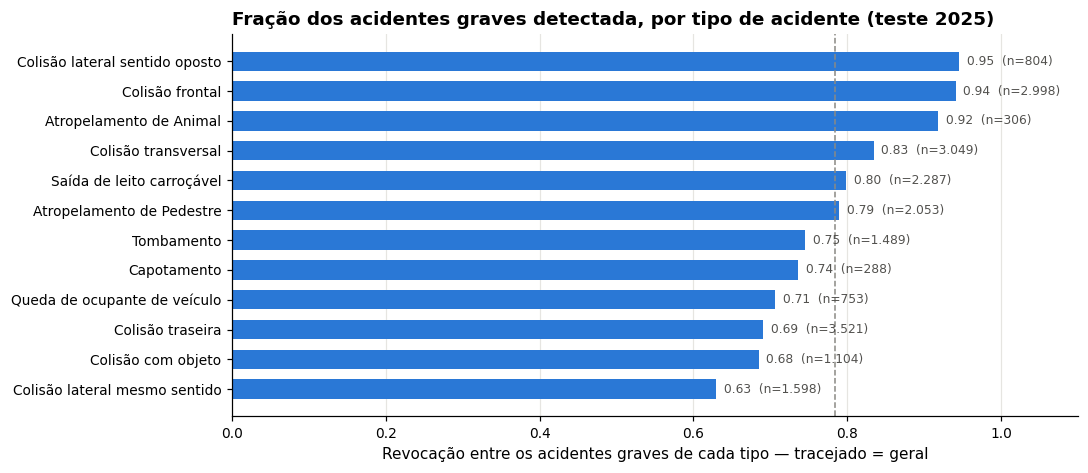

,graves NÃO detectados,graves detectados
quantidade,4437.000,16056.000
em área urbana (%),52.100,36.600
em pista simples (%),14.000,68.400
em plena noite (%),16.100,45.700
em fim de semana (%),26.500,36.400


In [52]:
graves = analise[analise["grave"] == 1]
por_tipo = graves.groupby("tipo_acidente")["previsto"].agg(graves="size", revocacao="mean")
por_tipo = por_tipo[por_tipo["graves"] >= 200].sort_values("revocacao")

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.barh(por_tipo.index, por_tipo["revocacao"], color=AZUL, height=0.65)
ax.axvline(por_grupo.loc["Brasil", "Revocação"], color=CINZA, linestyle="--", linewidth=1)
for y, (v, n) in enumerate(zip(por_tipo["revocacao"], por_tipo["graves"])):
    ax.text(v + 0.01, y, f"{v:.2f}  (n={n:,})".replace(",", "."), va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.1)
ax.set_title("Fração dos acidentes graves detectada, por tipo de acidente (teste 2025)")
ax.set_xlabel("Revocação entre os acidentes graves de cada tipo — tracejado = geral")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

# Perfil dos falsos negativos (graves não detectados) comparado ao dos graves detectados
perdidos, achados = graves[graves["previsto"] == 0], graves[graves["previsto"] == 1]
perfil = pd.DataFrame({
    "graves NÃO detectados": [len(perdidos), perdidos["area_urbana"].mean() * 100, (perdidos["tipo_pista"] == "Simples").mean() * 100,
                              (perdidos["fase_dia"] == "Plena Noite").mean() * 100, perdidos["fim_de_semana"].mean() * 100],
    "graves detectados": [len(achados), achados["area_urbana"].mean() * 100, (achados["tipo_pista"] == "Simples").mean() * 100,
                          (achados["fase_dia"] == "Plena Noite").mean() * 100, achados["fim_de_semana"].mean() * 100],
}, index=["quantidade", "em área urbana (%)", "em pista simples (%)", "em plena noite (%)", "em fim de semana (%)"])
perfil.round(1)

**Leitura.**
- O modelo detecta quase todas as **colisões frontais** graves (94%) e as laterais em sentido oposto (95%), mesmo sem conhecer o tipo do acidente. Esses acidentes se concentram em pista simples, e o modelo aprendeu essa associação.
- Ele detecta menos as **colisões traseiras** (69%) e as **laterais no mesmo sentido** (63%) que terminam em vítima grave. São acidentes típicos de pista dupla e de área urbana, contextos que o modelo trata como de baixo risco.
- O perfil dos casos graves não detectados confirma: só 14,0% ocorreram em pista simples (contra 68,4% dos detectados), 16,1% em plena noite (contra 45,7%) e 52,1% em área urbana (contra 36,6%).

O modelo aprendeu essencialmente a regra "pista simples, à noite, fora da cidade". Os acidentes graves que fogem desse padrão — de dia, em pista dupla, em área urbana — são os que ele perde, e o contexto disponível na base não oferece nada que os distinga.

### 10.3 Em quais atributos o modelo se apoia?

A importância por permutação mede quanto a PR-AUC cai quando os valores de um atributo são embaralhados: se a queda é grande, o modelo depende dele. É calculada na **validação** (não no treino, para não premiar memorização, e não no teste, para mantê-lo intocado), em uma amostra de 20 mil acidentes, com três repetições.

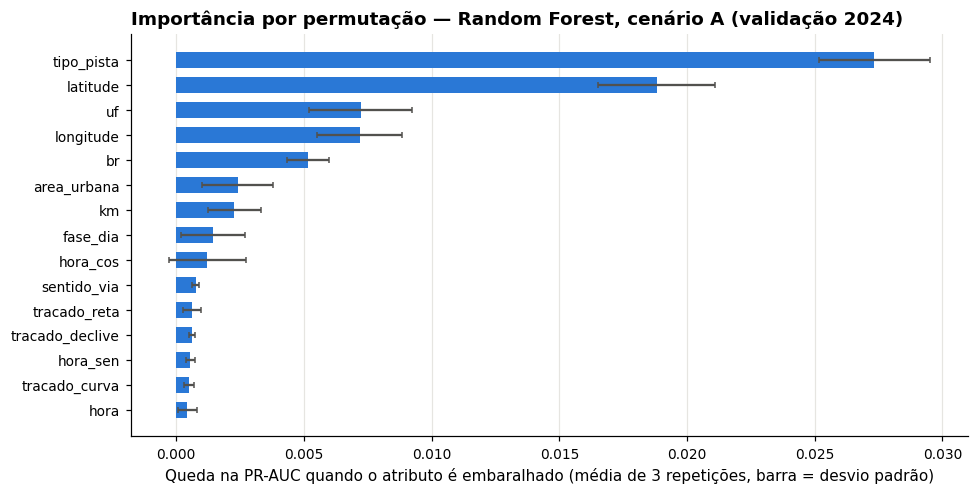

,queda,desvio
tipo_pista,0.027,0.002
latitude,0.019,0.002
uf,0.007,0.002
longitude,0.007,0.002
br,0.005,0.001
area_urbana,0.002,0.001
km,0.002,0.001
fase_dia,0.001,0.001


In [60]:
amostra = validacao.sample(20000, random_state=SEMENTE)
importancia = permutation_importance(modelos[CHAVE], amostra[colunas_a], amostra["grave"], scoring="average_precision",
                                     n_repeats=3, random_state=SEMENTE, n_jobs=-1)
imp = pd.DataFrame({"queda": importancia.importances_mean, "desvio": importancia.importances_std}, index=colunas_a)
imp = imp.sort_values("queda").tail(15)

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(imp.index, imp["queda"], xerr=imp["desvio"], color=AZUL, height=0.65, ecolor="#52514e", capsize=2)
ax.set_title("Importância por permutação — Random Forest, cenário A (validação 2024)")
ax.set_xlabel("Queda na PR-AUC quando o atributo é embaralhado (média de 3 repetições, barra = desvio padrão)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
imp.sort_values("queda", ascending=False).head(8).round(4)

**Leitura.** O modelo se apoia em poucos atributos. `tipo_pista` é o mais importante (queda de 0,027 na PR-AUC quando embaralhado), seguido dos atributos de localização: `latitude` (0,019), `uf`, `longitude` e `br`. Os atributos de horário têm efeito pequeno, e clima e traçado da via têm efeito próximo de zero, com barras de erro que encostam no zero.

Isso é coerente com as Seções 5.3 e 5.4 e com a análise por região: o modelo responde principalmente a *que tipo de pista* e *em que parte do país*. A importância por permutação tem uma limitação conhecida: quando atributos são correlacionados (latitude, longitude, UF e BR descrevem a mesma coisa), embaralhar um deles é parcialmente compensado pelos outros, e a importância de cada um fica subestimada. O peso conjunto da localização é, portanto, maior do que cada barra sugere.

### 10.4 As probabilidades do modelo podem ser lidas como risco?

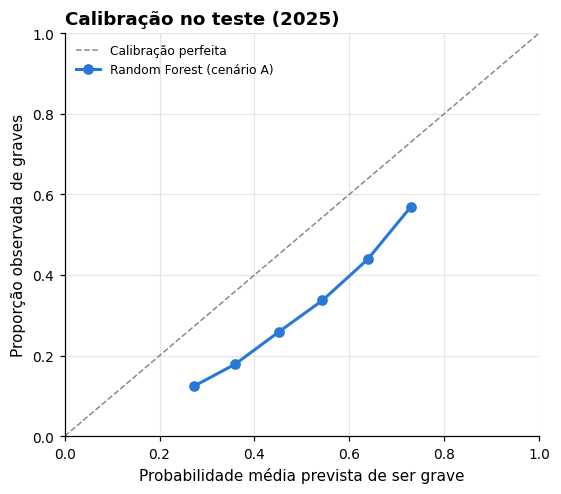

,previsto_medio,observado,acidentes
prob,,,
"(0.2, 0.3]",0.274,0.125,2538
"(0.3, 0.4]",0.359,0.179,14646
"(0.4, 0.5]",0.451,0.259,27219
"(0.5, 0.6]",0.543,0.337,19642
"(0.6, 0.7]",0.639,0.439,7118
"(0.7, 0.8]",0.729,0.568,1362


In [59]:
faixas = pd.cut(analise["prob"], bins=np.linspace(0, 1, 11))
calibracao = analise.groupby(faixas, observed=True).agg(previsto_medio=("prob", "mean"), observado=("grave", "mean"), acidentes=("grave", "size"))
calibracao = calibracao[calibracao["acidentes"] >= 100]      # faixas com poucos casos não são confiáveis

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=CINZA, linestyle="--", linewidth=1, label="Calibração perfeita")
ax.plot(calibracao["previsto_medio"], calibracao["observado"], color=AZUL, marker="o", linewidth=2, label="Random Forest (cenário A)")
ax.set_title("Calibração no teste (2025)")
ax.set_xlabel("Probabilidade média prevista de ser grave")
ax.set_ylabel("Proporção observada de graves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
calibracao.round(3)

**Leitura.** As probabilidades do modelo **superestimam** o risco em toda a faixa: entre os acidentes com nota em torno de 0,45, apenas 26% são graves. Isso é consequência direta de `class_weight="balanced"`, que faz o modelo se comportar como se as duas classes tivessem o mesmo tamanho. A ordem das notas é informativa (a proporção observada cresce junto com a nota), mas o valor não pode ser lido como probabilidade. Para comunicar risco a um usuário seria necessário calibrar o modelo (por exemplo, com regressão isotônica ajustada na validação).

### 10.5 Demonstração: o modelo diante de acidentes reais e simulados

**Como se sabe se o modelo "funcionou".** O teste já foi feito na Seção 8: os acidentes de 2025 ficaram escondidos durante todo o desenvolvimento, o modelo deu uma nota de risco para cada um, e as notas foram comparadas com o que realmente aconteceu. As métricas resumem esse confronto em números. Esta seção mostra o mesmo processo caso a caso, para que se possa ver o que o modelo responde e quando ele erra.

**Acidentes reais de 2025.** Quatro acidentes graves e quatro não graves sorteados do conjunto de teste, com a nota que o modelo do cenário A deu a cada um. O modelo não viu nenhum deles no treino.

In [55]:
colunas_bruto = ["data_inversa", "horario", "municipio", "mortos", "feridos_graves"]
exemplos = pd.concat([analise[analise["grave"] == 1].sample(4, random_state=SEMENTE),
                      analise[analise["grave"] == 0].sample(4, random_state=SEMENTE)])
exemplos = exemplos.join(bruto[colunas_bruto])
casos_reais = pd.DataFrame({
    "data": exemplos["data_inversa"], "hora": exemplos["horario"].str[:5],
    "local": exemplos["br"] + " / " + exemplos["municipio"].str.title() + " (" + exemplos["uf"] + ")",
    "pista": exemplos["tipo_pista"], "fase do dia": exemplos["fase_dia"], "clima": exemplos["condicao_metereologica"],
    "nota do modelo": exemplos["prob"].round(3),
    "previsão": exemplos["previsto"].map({1: "grave", 0: "não grave"}),
    "o que aconteceu": exemplos["grave"].map({1: "grave", 0: "não grave"}),
    "vítimas graves (mortos + feridos graves)": exemplos["mortos"] + exemplos["feridos_graves"],
}).sort_values("nota do modelo", ascending=False)
casos_reais["acertou?"] = np.where(casos_reais["previsão"] == casos_reais["o que aconteceu"], "sim", "não")
print(f"Limiar de decisão (escolhido na validação de 2024): nota >= {limiares[CHAVE]:.3f} -> 'grave'")
casos_reais

Limiar de decisão (escolhido na validação de 2024): nota >= 0.427 -> 'grave'


,data,hora,local,pista,fase do dia,clima,nota do modelo,previsão,o que aconteceu,vítimas graves (mortos + feridos graves),acertou?
295779,2025-02-20,16:30,BR-116 / Horizonte (CE),Dupla,Pleno dia,Nublado,0.487,grave,não grave,0,não
321923,2025-07-15,11:00,BR-282 / Palhoca (SC),Simples,Pleno dia,Céu Claro,0.477,grave,grave,1,sim
335849,2025-11-22,14:30,BR-135 / Sao Luis (MA),Dupla,Pleno dia,Céu Claro,0.476,grave,grave,1,sim
274607,2025-04-07,11:50,BR-116 / Vitoria Da Conquista (BA),Simples,Pleno dia,Nublado,0.474,grave,não grave,0,não
298040,2025-03-08,10:30,BR-365 / Patos De Minas (MG),Simples,Pleno dia,Sol,0.462,grave,não grave,0,não
277508,2025-06-06,02:30,BR-116 / Sao Jose Dos Pinhais (PR),Dupla,Plena Noite,Céu Claro,0.441,grave,grave,1,sim
304302,2025-04-21,16:20,BR-101 / Camboriu (SC),Dupla,Pleno dia,Céu Claro,0.416,não grave,não grave,0,sim
337471,2025-12-02,13:00,BR-116 / Pindamonhangaba (SP),Dupla,Pleno dia,Chuva,0.305,não grave,grave,1,não


**Acidentes simulados.** A função `simular_acidente` monta um acidente hipotético apenas com os atributos de contexto, os únicos que o modelo principal usa, e devolve:

- a **nota do modelo** e a **previsão** com o mesmo limiar da Seção 8;
- a **proporção de graves entre os acidentes reais de 2025 que receberam nota parecida** (diferença de até 0,02). Como as notas não estão calibradas (Seção 10.4), é esse número, e não a nota, que pode ser lido como risco.

As coordenadas não precisam ser informadas: a função usa as do acidente registrado em 2021–2023 mais próximo do quilômetro indicado, na mesma rodovia e UF.

In [56]:
DIAS_DA_SEMANA = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]


def simular_acidente(uf, br, km, data, horario, tipo_pista, condicao_metereologica="Céu Claro",
                     tracado_via="Reta", area_urbana=False, sentido_via="Crescente", fase_dia=None):
    """Monta um acidente hipotético só com atributos de contexto e aplica o modelo principal (cenário A)."""
    trecho = treino[(treino["uf"] == uf) & (treino["br"] == f"BR-{br}")]
    if trecho.empty:
        raise ValueError(f"Não há acidentes de 2021–2023 na BR-{br} em {uf} para obter as coordenadas.")
    vizinho = trecho.loc[(trecho["km"] - km).abs().idxmin()]
    hora = int(horario[:2])
    if fase_dia is None:   # regra aproximada, igual à predominante na base
        fase_dia = "Amanhecer" if hora == 5 else "Pleno dia" if 6 <= hora <= 17 else "Plena Noite"
    data = pd.Timestamp(data)
    linha = pd.DataFrame([{
        "ano": data.year, "grave": 0, "data_inversa": data.strftime("%Y-%m-%d"), "horario": horario,
        "dia_semana": DIAS_DA_SEMANA[data.dayofweek], "fase_dia": fase_dia, "uf": uf, "br": br, "km": str(km),
        "latitude": str(vizinho["latitude"]), "longitude": str(vizinho["longitude"]), "sentido_via": sentido_via,
        "condicao_metereologica": condicao_metereologica, "tipo_pista": tipo_pista,
        "uso_solo": "Sim" if area_urbana else "Não", "tracado_via": tracado_via,
        # As colunas abaixo não entram no modelo do cenário A; existem só para reaproveitar a função preparar().
        "tipo_acidente": "", "causa_acidente": "", "veiculos": 0, "pessoas": 0, "classificacao_acidente": "",
        "feridos_leves": 0, "ilesos": 0, "ignorados": 0,
    }])
    nota = float(prob_grave(modelos[CHAVE], preparar(linha)[colunas_a])[0])
    parecidos = analise[(analise["prob"] - nota).abs() <= 0.02]
    return {"nota do modelo": round(nota, 3),
            "previsão": "grave" if nota >= limiares[CHAVE] else "não grave",
            "graves entre acidentes reais de 2025 com nota parecida (%)": round(float(parecidos["grave"].mean()) * 100, 1),
            "acidentes reais com nota parecida": len(parecidos)}


simulacoes = {
    "1. BR-343 (PI), km 200, sábado 21h, pista simples, curva, fora da cidade":
        dict(uf="PI", br=343, km=200, data="2026-11-21", horario="21:00:00", tipo_pista="Simples", tracado_via="Curva"),
    "2. Mesmo local, terça 10h, pista simples, reta":
        dict(uf="PI", br=343, km=200, data="2026-11-17", horario="10:00:00", tipo_pista="Simples"),
    "3. BR-343 em Teresina (km 335), terça 10h, pista dupla, área urbana":
        dict(uf="PI", br=343, km=335, data="2026-11-17", horario="10:00:00", tipo_pista="Dupla", area_urbana=True),
    "4. BR-116 (SP), km 220, terça 10h, pista múltipla, área urbana, chuva":
        dict(uf="SP", br=116, km=220, data="2026-11-17", horario="10:00:00", tipo_pista="Múltipla",
             area_urbana=True, condicao_metereologica="Chuva"),
}
pd.DataFrame({nome: simular_acidente(**parametros) for nome, parametros in simulacoes.items()}).T

,nota do modelo,previsão,graves entre acidentes reais de 2025 com nota parecida (%),acidentes reais com nota parecida
"1. BR-343 (PI), km 200, sábado 21h, pista simples, curva, fora da cidade",0.697,grave,49.500,1390
"2. Mesmo local, terça 10h, pista simples, reta",0.593,grave,38.500,5317
"3. BR-343 em Teresina (km 335), terça 10h, pista dupla, área urbana",0.474,grave,28.000,11337
"4. BR-116 (SP), km 220, terça 10h, pista múltipla, área urbana, chuva",0.250,não grave,11.500,875


**Experimente.** Altere os valores abaixo e execute a célula. Valores aceitos: `tipo_pista` em "Simples", "Dupla" ou "Múltipla"; `condicao_metereologica` em "Céu Claro", "Nublado", "Chuva", "Garoa/Chuvisco", "Sol", "Nevoeiro/Neblina", "Vento" ou "Ignorado"; `tracado_via` em "Reta", "Curva", "Aclive", "Declive", "Interseção de Vias", "Rotatória", "Ponte", "Viaduto", combináveis com ponto e vírgula (por exemplo, "Curva;Declive").

In [57]:
pd.Series(simular_acidente(uf="PI", br=316, km=10, data="2026-12-24", horario="23:30:00", tipo_pista="Simples",
                           condicao_metereologica="Chuva", tracado_via="Curva;Declive", area_urbana=False))

,0
nota do modelo,0.633
previsão,grave
graves entre acidentes reais de 2025 com nota parecida (%),42.700
acidentes reais com nota parecida,3463


**Leitura.**
- **Casos reais.** Dos oito acidentes sorteados, o modelo acertou quatro. O padrão dos erros é o mesmo da Seção 8.1: ele dá notas acima do limiar para a maior parte dos acidentes e, por isso, marca como graves três acidentes que não foram. O acidente grave que ele deixou passar ocorreu de dia, com chuva, em pista dupla em São Paulo, exatamente o perfil que a Seção 10.2 identificou como o ponto cego do modelo.
- **Simulações.** O modelo ordena os cenários de forma coerente com a análise exploratória. No primeiro cenário (BR-343 no Piauí, sábado à noite, pista simples, curva, fora da cidade), 49,5% dos acidentes reais de 2025 com nota parecida foram graves, cerca de 1,7 vez a média nacional de 28,3%. No mesmo trecho em uma terça de manhã, a proporção cai para 38,5%; em Teresina, em pista dupla e área urbana, para 28,0%; e em um trecho urbano de pista múltipla da BR-116 em São Paulo, para 11,5%.
- **A nota não é risco.** No terceiro cenário a nota é 0,474, acima do limiar, e o modelo responde "grave". Mas entre os acidentes reais com nota parecida, só 28,0% foram graves, praticamente a média. A previsão "grave" significa apenas "acima do limiar escolhido para encontrar a maioria dos casos graves", não "provavelmente grave".
- **Associação, não causa.** A diferença entre os cenários reflete o que costuma acontecer em acidentes com aquele contexto. Ela não diz que mudar o horário ou a pista de um acidente específico mudaria seu desfecho.

## 11. Comparação com trabalhos relacionados

*ATENÇÃO (autor): os valores atribuídos a outros trabalhos nesta seção vieram de resumos e precisam ser conferidos nos artigos originais antes da entrega.*

| Trabalho | Dados | Abordagem | Diferença para este trabalho |
|---|---|---|---|
| Gabardo et al. (BRACIS 2025) | PRF, região Sul, 2021–2024 | Random Forest, kNN e MLP; SMOTE; SHAP | Desfecho fatal; uma região; reamostragem sintética. |
| Estudo do Rio de Janeiro (REIC/SBC 2025) | PRF, RJ, 2020–2023 | Vários classificadores | Relata Random Forest com 86% de acurácia e F1 de 59% usando dados de veículo e ambiente. |
| Santa Catarina (ERBD/SBC 2025) | PRF, SC | RF, SVM e MLP antes e depois de limpeza dos dados | Foco na qualidade do registro. |
| **Este trabalho** | PRF, Brasil, 2021–2025 | Regressão logística e Random Forest; três conjuntos de atributos; divisão temporal | Separa o que é previsível antes e depois do acidente e mede o efeito do vazamento. |

**A comparação numérica direta não é possível**: os trabalhos diferem na definição do rótulo, na região, no período e nos atributos. O que se pode comparar é o padrão dos resultados:

- O par "acurácia alta, F1 moderado" relatado para o Rio de Janeiro é o mesmo fenômeno medido aqui. Com cerca de 72% de acidentes não graves, a acurácia de 0,717 é obtida sem modelo nenhum (Seção 8.1). Acurácia não é uma métrica adequada para este problema.
- O F1 do cenário B deste trabalho (0,51), que usa atributos da dinâmica do acidente como os trabalhos relacionados, está na mesma ordem de grandeza do F1 relatado para o Rio de Janeiro. Os resultados são compatíveis com a literatura quando os atributos são comparáveis.
- A contribuição deste trabalho é mostrar **de onde vem o desempenho**: do contexto sozinho vem pouco (PR-AUC 0,40), a dinâmica do acidente acrescenta bastante (0,53), e colunas de desfecho levam a um resultado quase perfeito e sem valor prático (0,97–0,99).

## 12. Conclusões

**Resposta à pergunta de pesquisa.** A gravidade de um acidente em rodovia federal é **pouco previsível apenas pelo contexto**. Com local, horário, clima e características da via, o melhor modelo atinge PR-AUC de 0,395 no ano de teste, contra 0,283 sem modelo, e ROC-AUC de 0,627. O sinal existe e é estável, mas é insuficiente para classificar ocorrências individuais com confiança.

**Síntese dos resultados (teste, 2025).**

| Resultado | Evidência |
|---|---|
| O contexto tem sinal fraco | PR-AUC 0,395 contra 0,283 de base; F1 0,465 contra 0,441 de "sempre grave". |
| Informação posterior ao acidente explica mais | PR-AUC 0,528 com tipo, causa, veículos e pessoas. |
| Colunas de desfecho inflam o resultado | PR-AUC 0,97–0,99 com vazamento. |
| O modelo complexo ganha pouco do simples | Random Forest supera a regressão logística por cerca de 0,01 em PR-AUC. |
| A divisão temporal não mudou a conclusão | Diferença de até 0,005 em relação à divisão aleatória (resultado negativo). |
| O desempenho é desigual entre regiões | Alerta para 99,0% dos acidentes do Piauí e 54% dos do Sudeste. |

**Limitações.**
- A base só contém acidentes registrados. O modelo não estima a chance de um acidente acontecer, e o sub-registro de acidentes leves pode variar entre regiões.
- Faltam variáveis que provavelmente explicam a gravidade: velocidade, uso de cinto e capacete, tipo e idade dos veículos, volume de tráfego, tempo até o socorro. Parte delas existe na versão "por pessoa" da base da PRF.
- O rótulo junta mortos e feridos graves, e a classificação de "ferido grave" é feita no local pelo policial.
- Apenas dois algoritmos foram comparados, com uma busca pequena de hiperparâmetros. Os resultados sugerem que o limite está nos dados, mas isso não foi testado com outros modelos.
- As probabilidades não estão calibradas (Seção 10.4).
- O horário é aproximado em boa parte dos registros, e a contagem de pessoas diverge da soma das categorias em 5,4% dos acidentes (Seção 3.2).
- O modelo avaliado no teste foi treinado apenas com 2021–2023. Retreinar com 2024 incluído antes do teste provavelmente daria um resultado um pouco melhor; optou-se por não fazê-lo para manter o limiar escolhido na validação coerente com o modelo avaliado.

**Riscos e vieses.** O modelo aprende principalmente tipo de pista e localização. Usado sem cuidado, reproduziria a desigualdade regional dos dados: prioridade automática para o Norte e o Nordeste e menor detecção no Sul e no Sudeste. Além disso, se a diferença regional vier em parte de sub-registro, o modelo estaria aprendendo um artefato da coleta. Não deve ser usado para decisões sobre ocorrências individuais.

**Impacto possível.** O uso defensável é agregado: apoiar o planejamento ao indicar combinações de trecho, tipo de pista e horário com maior proporção de desfechos graves, sempre junto com a contagem de acidentes.

**Próximos passos.**
1. Usar a base por pessoa e por veículo da PRF para incluir tipo de veículo e perfil dos envolvidos.
2. Treinar e avaliar modelos por região, ou ajustar limiares por região.
3. Calibrar as probabilidades e avaliar o custo de alarmes falsos com apoio de especialistas.
4. Agregar por trecho de rodovia para estimar a taxa de acidentes graves por quilômetro, o que exigiria dados de volume de tráfego.

## Apêndice — Figuras do artigo

O artigo é escrito em inglês. As células abaixo geram, a partir dos mesmos resultados calculados acima, as versões em inglês das três figuras usadas no artigo e as salvam na pasta `figuras/`. Nenhum número novo é calculado aqui.

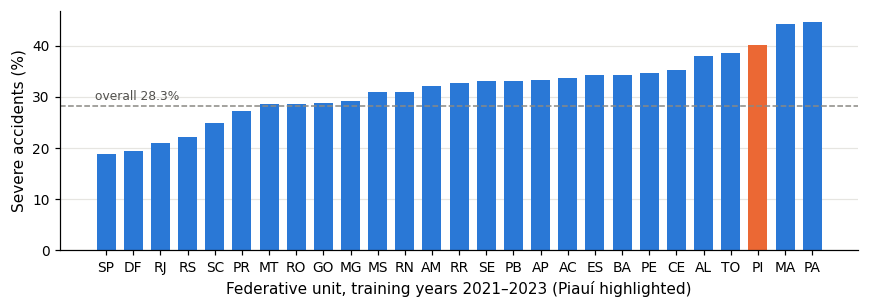

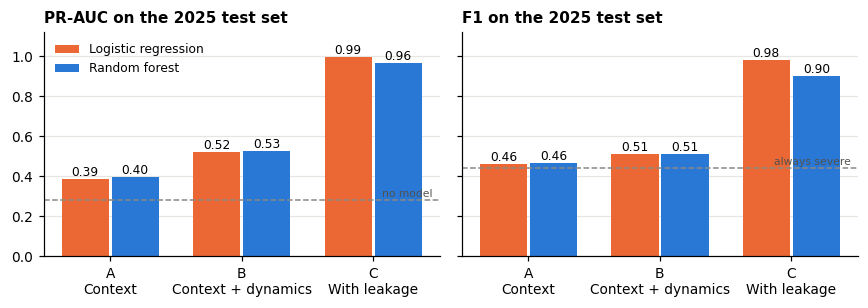

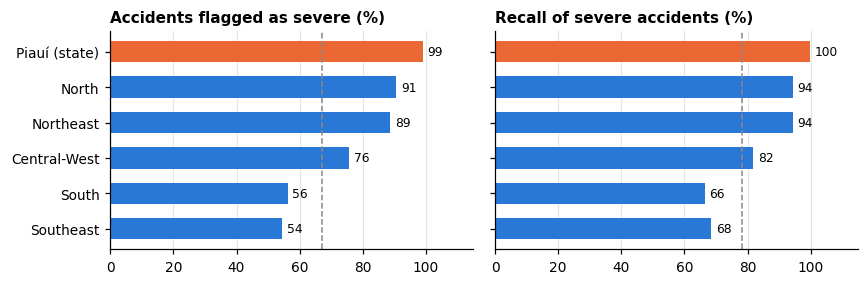

In [58]:
PASTA_FIGURAS = Path("figuras")
PASTA_FIGURAS.mkdir(exist_ok=True)

# Figura 1 — proporção de acidentes graves por UF
fig, ax = plt.subplots(figsize=(8, 2.9))
ax.bar(por_uf.index, por_uf["proporcao"] * 100, color=[LARANJA if uf == "PI" else AZUL for uf in por_uf.index], width=0.7)
ax.axhline(media_geral, color=CINZA, linestyle="--", linewidth=1)
ax.text(-0.4, media_geral + 1.0, f"overall {media_geral:.1f}%", fontsize=8, color="#52514e")
ax.set_ylabel("Severe accidents (%)")
ax.set_xlabel("Federative unit, training years 2021–2023 (Piauí highlighted)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig_uf.pdf")
plt.show()

# Figura 2 — desempenho por conjunto de atributos
nomes_en = ["A\nContext", "B\nContext + dynamics", "C\nWith leakage"]
fig, eixos = plt.subplots(1, 2, figsize=(8, 2.9), sharey=True)
for ax, metrica in zip(eixos, ["PR-AUC", "F1"]):
    for deslocamento, (nome, rotulo, cor) in zip([-0.19, 0.19], [("Regressão logística", "Logistic regression", LARANJA),
                                                                ("Random Forest", "Random forest", AZUL)]):
        valores = [tabela_cenarios.loc[(c, nome), metrica] for c in nomes_cenarios]
        ax.bar(x + deslocamento, valores, width=0.36, color=cor, label=rotulo)
        for xi, v in zip(x + deslocamento, valores):
            ax.text(xi, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
    referencia = y_teste.mean() if metrica == "PR-AUC" else tabela_a.loc["Sempre grave", "F1"]
    ax.axhline(referencia, color=CINZA, linestyle="--", linewidth=1)
    ax.text(2.45, referencia + 0.015, "no model" if metrica == "PR-AUC" else "always severe", ha="right", fontsize=7, color="#52514e")
    ax.set_xticks(x, nomes_en)
    ax.set_ylim(0, 1.12)
    ax.set_title(f"{metrica} on the 2025 test set", fontsize=10)
    ax.grid(axis="x", visible=False)
eixos[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig_feature_sets.pdf")
plt.show()

# Figura 3 — revocação e fração de alertas por região
regioes_en = {"Norte": "North", "Nordeste": "Northeast", "Centro-Oeste": "Central-West", "Sudeste": "Southeast", "Sul": "South", "Piauí": "Piauí (state)"}
ordem_en = por_grupo.drop(index="Brasil").sort_values("alertas (%)")
fig, eixos = plt.subplots(1, 2, figsize=(8, 2.7), sharey=True)
for ax, (coluna, titulo, escala) in zip(eixos, [("alertas (%)", "Accidents flagged as severe (%)", 1), ("Revocação", "Recall of severe accidents (%)", 100)]):
    valores = ordem_en[coluna] * escala
    ax.barh([regioes_en[i] for i in ordem_en.index], valores, color=[LARANJA if i == "Piauí" else AZUL for i in ordem_en.index], height=0.6)
    ax.axvline(por_grupo.loc["Brasil", coluna] * escala, color=CINZA, linestyle="--", linewidth=1)
    for y, v in enumerate(valores):
        ax.text(v + 1.5, y, f"{v:.0f}", va="center", fontsize=8)
    ax.set_xlim(0, 115)
    ax.set_title(titulo, fontsize=10)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig_regions.pdf")
plt.show()

## 13. Transparência

**Dados.** Polícia Rodoviária Federal — Dados Abertos, Acidentes agrupados por ocorrência, 2021–2025: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf>

**Notebook.** *PREENCHER: link público do notebook no Colab ou Kaggle.*

**Uso de modelos de linguagem (LLMs).** *PREENCHER com a sua declaração. Rascunho factual:* Foi utilizado o assistente Claude (Anthropic), via Claude Code, para: leitura do enunciado e planejamento das etapas; busca inicial de trabalhos relacionados; geração do código e da primeira versão dos textos deste notebook; e depuração. O autor revisou e executou todas as células, conferiu os resultados contra os dados e leu os trabalhos citados nas fontes originais. Respostas do assistente não foram usadas como fonte científica.

## Referências

*PREENCHER com a referência completa de cada trabalho, conferida no original.*

1. Polícia Rodoviária Federal. *Dados Abertos da PRF — Acidentes*. Disponível em: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf>. Acesso em: 16 nov. 2026.
2. Gabardo et al. *Highway to... Determining Fatal Outcomes in Traffic Accidents Based on Police Reports*. BRACIS 2025. <https://sol.sbc.org.br/index.php/bracis/article/view/40861>
3. Estudo sobre gravidade de acidentes nas rodovias federais do Rio de Janeiro (2020–2023). REIC/SBC, 2025. <https://journals-sol.sbc.org.br/index.php/reic/article/download/6274/3563/33284>
4. *Predição de acidentes rodoviários em Santa Catarina: impactos de aperfeiçoamentos dos dados*. ERBD/SBC, 2025. <https://sol.sbc.org.br/index.php/erbd/article/view/35405>
5. Pedregosa et al. *Scikit-learn: Machine Learning in Python*. JMLR 12, 2011.
6. Breiman, L. *Random Forests*. Machine Learning 45, 2001.